# Netflix: análise exploratória e preparação para Streamlit

Base de 7.786 títulos com informações IMDb e TMDb. Notebook adaptado da EDA do aluno para execução local e exportação dos dados da Aula 21.

Origem do notebook: https://colab.research.google.com/drive/1LBwfll2VYpDFk61nXW9KonxWqa0oK7wt

Fonte dos registros: arquivo `netflix_content_intelligence_combined.csv` fornecido pelo aluno. O endereço público original e a licença ainda precisam ser documentados; não foram inferidos.


## Setup de Bibliotecas e Dados

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

COR_NEUTRA = "lightgray"
COR_CONTEXTO = "#e9d4d0"
COR_DESTAQUE = "#2d223a"
COR_ALERTA = "tab:red"

Matplotlib is building the font cache; this may take a moment.


## Carregando o Dataset

In [2]:
from pathlib import Path
import pandas as pd

# Funciona na raiz do projeto, na pasta notebooks/ e no Colab.
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PASTA_RAW = RAIZ / "data" / "raw"
PASTA_CLEAN = RAIZ / "data" / "clean"
PASTA_RAW.mkdir(parents=True, exist_ok=True)
PASTA_CLEAN.mkdir(parents=True, exist_ok=True)
arquivo_raw = PASTA_RAW / "dataset.csv"

if arquivo_raw.exists():
    df_raw = pd.read_csv(arquivo_raw)
else:
    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError("Copie o CSV original para data/raw/dataset.csv antes de executar a EDA.")
    uploaded = files.upload()
    if len(uploaded) != 1:
        raise ValueError("Envie apenas o CSV original da Netflix.")
    from io import BytesIO
    df_raw = pd.read_csv(BytesIO(next(iter(uploaded.values()))))

df = df_raw.copy()
df.head()


,content_id,title,type,release_year,release_decade,release_year_group,content_age,date_added,rating,duration,...,primary_country,country_count,is_original,is_recent_release,has_rating,has_cast,has_director,data_completeness_score,match_method,match_confidence
0,nf_2879cda65363,3%,TV Show,2020,2020,2020-2022,6,"August 14, 2020",TV-MA,4 Seasons,...,Brazil,1,False,False,True,True,False,0.857,fuzzy_title_year,0.89
1,nf_73818ff7bd91,7:19,Movie,2016,2010,2016-2019,10,"December 23, 2016",TV-MA,93 min,...,Mexico,1,False,False,True,True,True,1.000,exact_title_year,0.90
2,nf_821496e58bca,23:59,Movie,2011,2010,2010-2015,15,"December 20, 2018",R,78 min,...,Singapore,1,False,False,True,True,True,1.000,exact_title_year,0.90
3,nf_be2013d8c4ac,9,Movie,2009,2000,2000s,17,"November 16, 2017",PG-13,80 min,...,United States,1,False,False,True,True,True,1.000,exact_title_year,0.90
4,nf_f4e65f8e18a8,21,Movie,2008,2000,2000s,18,"January 1, 2020",PG-13,123 min,...,United States,1,False,False,True,True,True,1.000,exact_title_year,0.90


## 1. Princípio Estrutural

Verificamos dimensões, tipos, ausências e duplicatas da base de filmes e séries. Cada linha representa um título.


### Dimensão e Tipos de Dados

In [3]:
df.shape

(7786, 40)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7786 entries, 0 to 7785
Data columns (total 40 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   content_id               7786 non-null   object 
 1   title                    7786 non-null   object 
 2   type                     7786 non-null   object 
 3   release_year             7786 non-null   int64  
 4   release_decade           7786 non-null   int64  
 5   release_year_group       7786 non-null   object 
 6   content_age              7786 non-null   int64  
 7   date_added               7776 non-null   object 
 8   rating                   7779 non-null   object 
 9   duration                 7786 non-null   object 
 10  runtime_minutes          5115 non-null   float64
 11  description              7786 non-null   object 
 12  genres                   7786 non-null   object 
 13  countries                7279 non-null   object 
 14  languages               

In [5]:
df.describe()

,release_year,release_decade,content_age,runtime_minutes,tmdb_id,imdb_rating,imdb_votes,tmdb_rating,tmdb_popularity,popularity_percentile,genre_count,country_count,data_completeness_score,match_confidence
count,7786.000000,7786.000000,7786.000000,5115.000000,5.355000e+03,5460.000000,5.460000e+03,5355.000000,5355.000000,5355.000000,7786.000000,7786.000000,7786.000000,7786.000000
mean,2013.932571,2008.506293,12.067429,92.991202,2.842507e+05,6.405696,3.682077e+04,6.262976,3.856199,50.009337,2.192140,1.163755,0.842324,0.644053
std,8.757957,8.900565,8.757957,35.232610,2.293801e+05,1.163838,1.336174e+05,1.443067,5.810399,28.870209,0.786083,0.732072,0.176466,0.403060
min,1925.000000,1920.000000,5.000000,2.000000,1.400000e+01,1.500000,5.000000e+00,0.000000,0.014300,0.018674,1.000000,0.000000,0.286000,0.000000
25%,2013.000000,2010.000000,8.000000,80.000000,7.728900e+04,5.700000,5.475000e+02,5.726000,1.169000,25.014006,2.000000,1.000000,0.714000,0.000000
50%,2017.000000,2010.000000,9.000000,96.000000,2.739970e+05,6.500000,2.771000e+03,6.473000,2.106200,50.009337,2.000000,1.000000,0.857000,0.900000
75%,2018.000000,2010.000000,13.000000,112.000000,4.666020e+05,7.200000,1.488950e+04,7.113500,4.689900,75.004669,3.000000,1.000000,1.000000,0.900000
max,2021.000000,2020.000000,101.000000,542.000000,1.753955e+06,9.400000,2.858413e+06,10.000000,221.584600,100.000000,3.000000,12.000000,1.000000,0.900000


### Duplicadas

In [6]:
df.duplicated().sum()

np.int64(0)

### Renomeando o atributo alvo para facilitar a interpretação

A coluna type identifica os conteúdos como Movie ou TV Show. Para facilitar a interpretação das tabelas e dos gráficos, criaremos a coluna tipo_conteudo, com as categorias “Filme” e “Série”. A coluna original será preservada.

In [7]:

df["tipo_conteudo"] = df["type"].map({
    "Movie": "Filme",
    "TV Show": "Série"
})


df["tipo_conteudo"].value_counts()

tipo_conteudo
Filme    5376
Série    2410
Name: count, dtype: int64

## 2. Dados Faltantes

In [8]:
df.isna().sum()

content_id                    0
title                         0
type                          0
release_year                  0
release_decade                0
release_year_group            0
content_age                   0
date_added                   10
rating                        7
duration                      0
runtime_minutes            2671
description                   0
genres                        0
countries                   507
languages                  2431
original_language          2431
cast                        718
directors                  2389
imdb_id                    2190
tmdb_id                    2431
imdb_rating                2326
imdb_votes                 2326
tmdb_rating                2431
tmdb_popularity            2431
imdb_rating_category       2326
tmdb_rating_category       2431
popularity_category        2431
popularity_percentile      2431
primary_genre                 0
genre_count                   0
primary_country             507
country_

**Discussao:** Alguma feature tem dados ausentes nos seus dados?

*Resposta*: Sim. O dataset apresenta valores ausentes em diversas variáveis. Entre elas, runtime_minutes possui 2.671 ausências (34,31%), tmdb_rating e tmdb_popularity possuem 2.431 cada (31,22%), directors possui 2.389 (30,68%) e imdb_rating possui 2.326 (29,87%). Outras colunas apresentam poucas ausências, como date_added, com 10 registros, e rating, com 7. Isso mostra que a disponibilidade das informações varia entre as variáveis, sendo necessário investigar os motivos antes de decidir como tratá-las.

#### Identificando o mecanismo de dados ausentes

O dataset reúne informações de filmes e séries, incluindo características dos conteúdos e dados associados ao IMDb e ao TMDb. Algumas informações podem estar ausentes por indisponibilidade na fonte ou por dificuldades na correspondência dos títulos entre bases.

Para investigar essas possibilidades, analisaremos a coluna match_method, que registra o método de correspondência, e verificaremos se as ausências variam entre filmes e séries. Essas análises permitem identificar padrões, mas não comprovam, sozinhas, a causa das ausências.

**As ausências ocorrem juntas?**

Verificamos se IMDb e TMDb estão ausentes nos mesmos títulos e como esse padrão se relaciona ao método de correspondência entre fontes.


In [9]:

tabela_ausencias = pd.crosstab(
    df["match_method"],
    df["imdb_rating"].isna()
)

tabela_ausencias = tabela_ausencias.rename(columns={
    False: "Com nota IMDb",
    True: "Sem nota IMDb"
})

tabela_ausencias


imdb_rating,Com nota IMDb,Sem nota IMDb
match_method,,
exact_title_year,4969,102
fuzzy_title_year,491,34
unmatched,0,2190


Todos os 2.190 títulos classificados como unmatched estão sem nota IMDb. Esse padrão sugere que parte das ausências está relacionada à falta de correspondência entre as bases. Entretanto, também existem títulos com correspondência e sem nota, indicando que esse processo não explica todas as ausências.

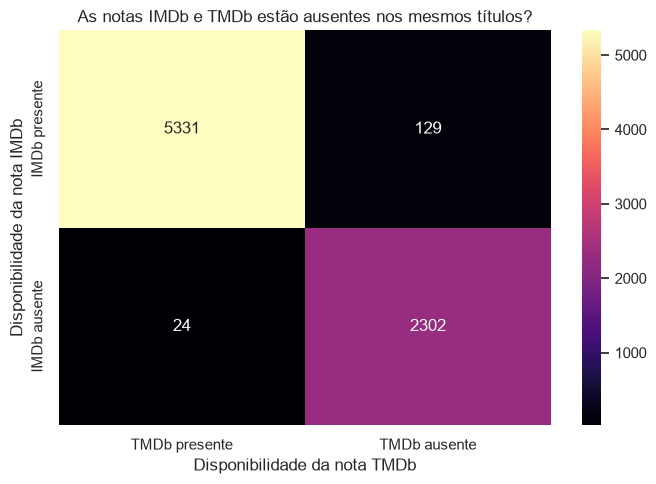

In [10]:

tabela_contingencia = pd.crosstab(
    df["imdb_rating"].isna(),
    df["tmdb_rating"].isna()
)


tabela_contingencia = tabela_contingencia.reindex(
    index=[False, True],
    columns=[False, True],
    fill_value=0
)

tabela_contingencia.index = ["IMDb presente", "IMDb ausente"]
tabela_contingencia.columns = ["TMDb presente", "TMDb ausente"]

plt.figure(figsize=(7, 5))

sns.heatmap(
    tabela_contingencia,
    annot=True,
    fmt="d",
    cmap="magma"
)

plt.title("As notas IMDb e TMDb estão ausentes nos mesmos títulos?")
plt.xlabel("Disponibilidade da nota TMDb")
plt.ylabel("Disponibilidade da nota IMDb")
plt.tight_layout()
plt.show()

2.302 linhas apresentam ausência simultânea em imdb_rating e tmdb_rating, correspondendo a 29,57% da base. Se essas ausências fossem independentes, esperaríamos aproximadamente 726 ocorrências conjuntas, considerando as proporções individuais. Portanto, o resultado sugere uma forte associação entre as ausências.

Uma possível explicação é a dificuldade de correspondência entre fontes: os 2.190 títulos classificados como unmatched estão sem ambas as notas. A associação com essa característica observada torna MAR uma hipótese a investigar e enfraquece a hipótese de ausência completamente aleatória (MCAR).

Entretanto, a ocorrência conjunta não determina o mecanismo. MNAR seria uma possibilidade se a chance de ausência dependesse da própria nota não observada, mesmo após considerar as informações disponíveis. Não temos evidências suficientes para afirmar isso. Precisaríamos conhecer o processo de coleta e integração; um teste de MCAR, isoladamente, não distinguiria MAR de MNAR.

Como a quantidade de ausências é expressiva, o heatmap é adequado para visualizar esse padrão. Para as próximas análises, manteremos a base completa e utilizaremos os registros com as informações necessárias em cada comparação, informando o tamanho do subconjunto e suas limitações.

## 3. Princípio Distribucional

Ainda com os dados originais (sem tratar ausentes ou outliers), vamos calcular as estatísticas descritivas e olhar as distribuições. Esse retrato "antes" é o que vai *orientar as decisões de tratamento* na próxima seção. Por exemplo, se uma variável for muito assimétrica, faz mais sentido imputar com a mediana do que com a média.

In [11]:
VARS_QUANT = [
    "release_year",
    "imdb_rating",
    "imdb_votes",
    "tmdb_rating",
    "tmdb_popularity"
]

VARS_QUALI = [
    "tipo_conteudo",
    "rating",
    "primary_genre",
    "primary_country"
]

desc = df[VARS_QUANT].describe().T

desc["skewness"] = df[VARS_QUANT].skew()
desc["kurtosis"] = df[VARS_QUANT].kurtosis()

desc[[
    "count", "mean", "50%", "std",
    "min", "max", "skewness", "kurtosis"
]].rename(
    columns={"50%": "median"}
).round(2)
desc = df[VARS_QUANT].describe().T
desc["skewness"] = df[VARS_QUANT].skew()
desc["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="magma", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
release_year,2013.93,2017.00,8.76,1925.00,2021.00,-3.62,17.56
imdb_rating,6.41,6.50,1.16,1.50,9.40,-0.67,0.61
imdb_votes,36820.77,2771.00,133617.42,5.00,2858413.00,9.39,127.14
tmdb_rating,6.26,6.47,1.44,0.00,10.00,-1.90,6.12
tmdb_popularity,3.86,2.11,5.81,0.01,221.58,13.13,393.95


Olhando a tabela, quais variáveis apresentam assimetria acentuada ou curtose elevada? Esses resultados são coerentes com o contexto de filmes, séries e avaliações?

As variáveis imdb_votes e tmdb_popularity apresentam forte assimetria positiva e curtose elevada. Isso indica uma concentração de títulos em valores menores, com poucos registros apresentando números muito altos de votos ou popularidade.

release_year apresenta forte assimetria negativa: a base concentra lançamentos em anos mais recentes, enquanto poucos títulos antigos prolongam a cauda à esquerda. tmdb_rating também apresenta assimetria negativa e curtose elevada, indicando uma cauda em direção às notas baixas.

Já imdb_rating apresenta assimetria negativa menos acentuada e curtose mais próxima de zero. Entre as variáveis selecionadas, sua distribuição é a mais próxima da simetria, embora isso não seja suficiente para afirmar normalidade.

Esses resultados são compatíveis com uma base em que poucos títulos concentram muita atenção e há maior presença de lançamentos relativamente recentes. Os histogramas ajudarão a verificar visualmente esses padrões.

Um ajuste na orientação do exemplo: assimetria negativa também importa — por isso observamos valores abaixo de −1, além dos acima de 1. Para a curtose calculada aqui, zero é a referência da distribuição normal; um valor negativo de grande magnitude não significa cauda pesada.

### Distribuições de dados

Primeiro, analisaremos a distribuição das variáveis quantitativas de todos os títulos, utilizando os valores disponíveis em cada coluna. Depois, compararemos filmes e séries para investigar possíveis diferenças entre os grupos.


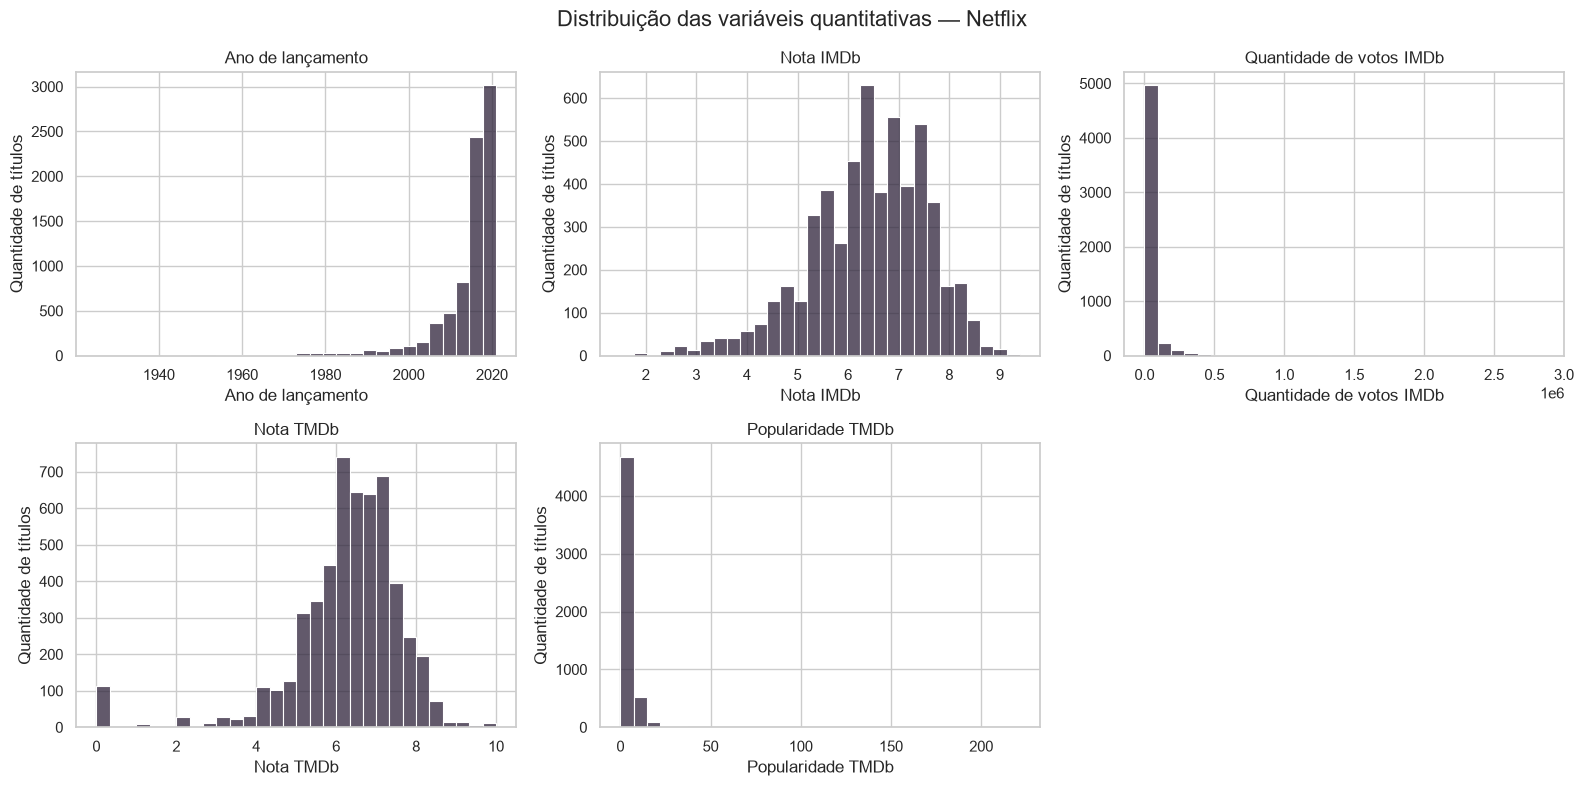

In [12]:
nomes_variaveis = {
    "release_year": "Ano de lançamento",
    "imdb_rating": "Nota IMDb",
    "imdb_votes": "Quantidade de votos IMDb",
    "tmdb_rating": "Nota TMDb",
    "tmdb_popularity": "Popularidade TMDb"
}

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.ravel()

for i, coluna in enumerate(VARS_QUANT):
    sns.histplot(
        data=df,
        x=coluna,
        bins=30,
        color=COR_DESTAQUE,
        ax=axes[i]
    )

    axes[i].set_title(nomes_variaveis[coluna])
    axes[i].set_xlabel(nomes_variaveis[coluna])
    axes[i].set_ylabel("Quantidade de títulos")


for ax in axes[len(VARS_QUANT):]:
    ax.axis("off")

fig.suptitle(
    "Distribuição das variáveis quantitativas — Netflix",
    fontsize=16
)

plt.tight_layout()
plt.show()

A distribuição dos anos de lançamento concentra-se nos anos mais recentes da base, com poucos títulos antigos. Isso é consistente com a assimetria negativa observada na tabela descritiva.

As notas IMDb concentram-se em torno de valores intermediários, com média de 6,41 e mediana de 6,50. Nas notas TMDb, a média de 6,26 fica abaixo da mediana de 6,47, em concordância com a assimetria em direção às notas menores.

Votos IMDb e popularidade TMDb apresentam valores máximos muito superiores aos valores típicos. Por isso, os histogramas na escala original podem concentrar grande parte dos títulos nas primeiras barras, dificultando a visualização das diferenças entre os valores menores.

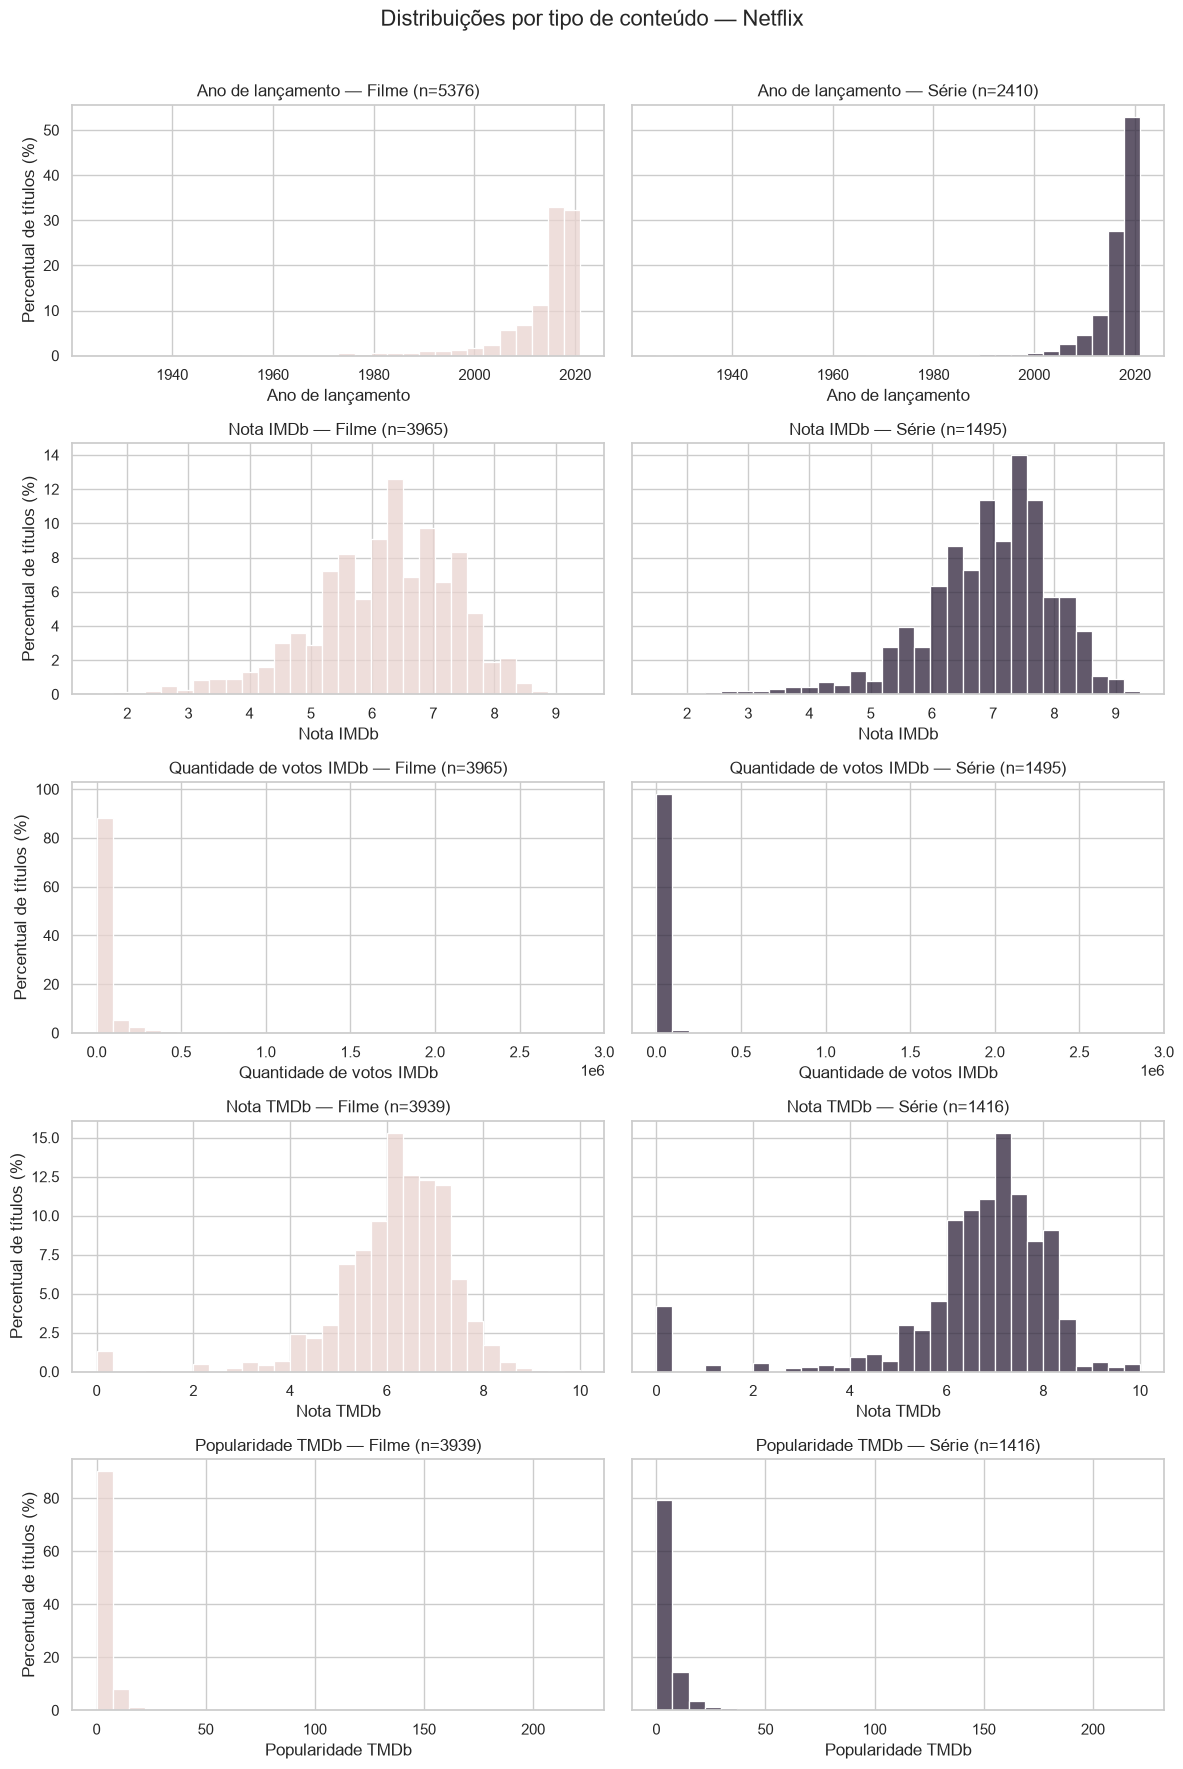

In [13]:
grupos = [
    ("Filme", COR_CONTEXTO),
    ("Série", COR_DESTAQUE)
]

fig, axes = plt.subplots(
    len(VARS_QUANT), 2,
    figsize=(12, 3.5 * len(VARS_QUANT)),
    sharex="row",
    sharey="row"
)

for i, coluna in enumerate(VARS_QUANT):

    valores = df[coluna].dropna()
    intervalos = np.histogram_bin_edges(valores, bins=30)

    for j, (grupo, cor) in enumerate(grupos):
        dados_grupo = df.loc[
            df["tipo_conteudo"] == grupo, coluna
        ].dropna()

        sns.histplot(
            x=dados_grupo,
            bins=intervalos,
            stat="percent",
            color=cor,
            ax=axes[i, j]
        )

        axes[i, j].set_title(
            f"{nomes_variaveis[coluna]} — {grupo} "
            f"(n={len(dados_grupo)})"
        )
        axes[i, j].set_xlabel(nomes_variaveis[coluna])
        axes[i, j].set_ylabel("Percentual de títulos (%)")

fig.suptitle(
    "Distribuições por tipo de conteúdo — Netflix",
    fontsize=16,
    y=1.01
)

plt.tight_layout()
plt.show()

Para discutir: alguma variável apresenta um formato de distribuição diferente entre filmes e séries, considerando as mesmas escalas e intervalos?

As séries apresentam notas IMDb mais altas entre os registros disponíveis: mediana de 7,1, contra 6,3 nos filmes. Também apresentam anos de lançamento mais recentes, com mediana de 2018, contra 2016. Os filmes possuem maior mediana de votos IMDb (3.839 contra 1.217), enquanto as séries apresentam maior mediana de popularidade TMDb (4,01 contra 1,66). Essas diferenças indicam que votos e popularidade são medidas distintas. As comparações de avaliações se limitam aos títulos com dados disponíveis.

In [14]:
df.groupby("tipo_conteudo")[VARS_QUANT].agg(
    ["count", "mean", "median", "std"]
).round(2)

release_year                        imdb_rating               \
                     count     mean  median   std       count  mean median   
tipo_conteudo                                                                
Filme                 5376  2012.92  2016.0  9.66        3965  6.21    6.3   
Série                 2410  2016.19  2018.0  5.66        1495  6.94    7.1   

                    imdb_votes                              tmdb_rating        \
                std      count      mean  median        std       count  mean   
tipo_conteudo                                                                   
Filme          1.14       3965  46980.58  3839.0  153577.91        3939  6.15   
Série          1.05       1495   9875.17  1217.0   40681.43        1416  6.57   

                           tmdb_popularity                     
              median   std           count  mean median   std  
tipo_conteudo                                                  
Filme           6.30  1.27            3939  3.17   1.66  4.41  
Série           6.97  1.80            1416  5.77   4.01  8.29

#### Testes de Aderência

Será que as notas IMDb seguem uma distribuição normal?

Utilizaremos o teste de Shapiro-Wilk e um QQ-plot para investigar a distribuição de imdb_rating. A hipótese nula considera que os dados vêm de uma distribuição normal. Adotaremos um nível de significância de 5%.

Notas disponíveis: 5460
Notas utilizadas no teste: 5000
Estatística W: 0.9731
P-valor: 1.166e-29
Rejeitamos a hipótese de normalidade.


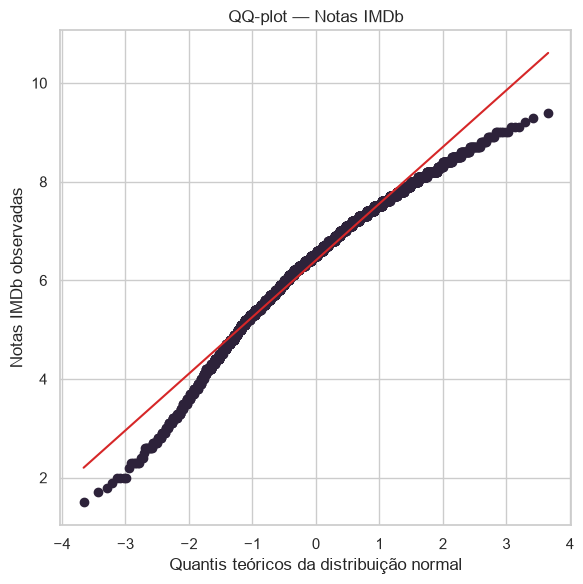

In [15]:

notas = df["imdb_rating"].dropna()


amostra = notas.sample(
    n=min(5000, len(notas)),
    random_state=42
)

stat_sw, p_valor_sw = stats.shapiro(amostra)

print(f"Notas disponíveis: {len(notas)}")
print(f"Notas utilizadas no teste: {len(amostra)}")
print(f"Estatística W: {stat_sw:.4f}")
print(f"P-valor: {p_valor_sw:.4g}")

if p_valor_sw < 0.05:
    print("Rejeitamos a hipótese de normalidade.")
else:
    print("Não rejeitamos a hipótese de normalidade.")


fig, ax = plt.subplots(figsize=(6, 6))

stats.probplot(notas, dist="norm", plot=ax)

ax.get_lines()[0].set_color(COR_DESTAQUE)
ax.get_lines()[1].set_color(COR_ALERTA)

ax.set_title("QQ-plot — Notas IMDb")
ax.set_xlabel("Quantis teóricos da distribuição normal")
ax.set_ylabel("Notas IMDb observadas")

plt.tight_layout()
plt.show()

Como ler: os pontos roxos representam as notas IMDb ordenadas, comparadas aos valores esperados de uma distribuição normal. Se acompanhassem aproximadamente a reta vermelha, isso indicaria compatibilidade visual com a normalidade. Desvios sistemáticos, principalmente nas extremidades, indicam diferenças nas caudas da distribuição.

Na nossa análise, a assimetria de aproximadamente −0,67 indica uma cauda mais prolongada em direção às notas baixas. O QQ-plot deve ser interpretado junto com esse resultado e com o histograma, observando como os pontos se afastam da reta. Além disso, as notas são limitadas à escala de avaliação e apresentam valores repetidos, podendo formar pequenos degraus no gráfico.

Tamanho da amostra: diferentemente do exemplo da aula, com aproximadamente 303 registros, temos 5.460 notas disponíveis no QQ-plot e utilizamos uma amostra aleatória de 5.000 notas no Shapiro-Wilk. Amostras grandes permitem detectar até pequenos desvios da normalidade. Por isso, um p-valor muito baixo não significa, sozinho, que a distribuição seja extremamente diferente de uma normal.

Conclusão: o teste apresentou p ≈ 1,17 × 10⁻²⁹, abaixo de 0,05. Portanto, temos evidência estatística contra a hipótese de normalidade das notas IMDb analisadas. Isso não significa que os dados estejam errados ou que devam ser excluídos. A intensidade e a relevância dos desvios precisam ser avaliadas também pelos gráficos.

Caso o teste não rejeitasse a hipótese nula, a conclusão seria que não encontramos evidência suficiente contra a normalidade, e não que a distribuição foi comprovadamente normal.

In [16]:
resultados_shapiro = []

for coluna in VARS_QUANT:
    valores = df[coluna].dropna()


    amostra = valores.sample(
        n=min(5000, len(valores)),
        random_state=42
    )

    estatistica, p_valor = stats.shapiro(amostra)

    resultados_shapiro.append({
        "Variável": coluna,
        "Valores disponíveis": len(valores),
        "Tamanho da amostra": len(amostra),
        "Estatística W": estatistica,
        "P-valor": p_valor,
        "Rejeita normalidade?": "Sim" if p_valor < 0.05 else "Não"
    })

tabela_shapiro = pd.DataFrame(
    resultados_shapiro
).set_index("Variável")

tabela_shapiro.style.format({
    "Estatística W": "{:.4f}",
    "P-valor": "{:.3e}"
})

,Valores disponíveis,Tamanho da amostra,Estatística W,P-valor,Rejeita normalidade?
Variável,,,,,
release_year,7786,5000,0.6132,1.072e-74,Sim
imdb_rating,5460,5000,0.9731,1.166e-29,Sim
imdb_votes,5460,5000,0.2724,1.802e-88,Sim
tmdb_rating,5355,5000,0.8518,4.614e-56,Sim
tmdb_popularity,5355,5000,0.4517,3.727e-82,Sim


Aplicamos o teste de Shapiro-Wilk separadamente às variáveis quantitativas selecionadas, utilizando amostras aleatórias de até 5.000 observações e nível de significância de 5%. A coluna “Rejeita normalidade?” indica se encontramos evidência estatística contra a normalidade de cada variável.

Como as amostras são grandes, os resultados devem ser interpretados junto aos histogramas, à assimetria e à curtose. Além disso, ano de lançamento e quantidade de votos são variáveis discretas, enquanto notas possuem limites definidos. Portanto, não esperamos que todas essas variáveis sigam exatamente uma distribuição normal, e a rejeição não caracteriza um erro nos dados.

A ECDF representa a proporção acumulada das observações. Vamos comparar as notas IMDb de filmes e séries, considerando apenas os títulos com nota disponível. Diferentemente do histograma, esse gráfico não depende da escolha de intervalos.

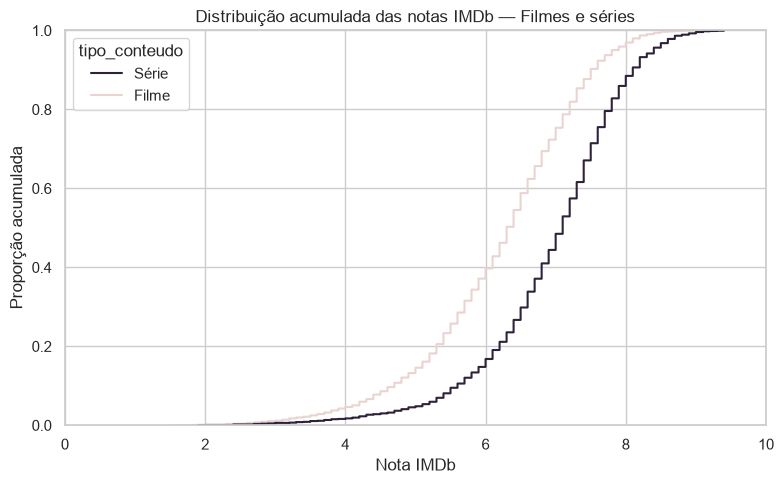

In [17]:
plt.figure(figsize=(8, 5))

sns.ecdfplot(
    data=df,
    x="imdb_rating",
    hue="tipo_conteudo",
    palette={
        "Filme": COR_CONTEXTO,
        "Série": COR_DESTAQUE
    }
)

plt.title("Distribuição acumulada das notas IMDb — Filmes e séries")
plt.xlabel("Nota IMDb")
plt.ylabel("Proporção acumulada")
plt.xlim(0, 10)
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

Como ler: escolha uma nota no eixo horizontal e observe a altura de cada curva. Por exemplo, se uma curva atingir 0,70 na nota 7, isso significa que 70% dos títulos daquele grupo possuem nota menor ou igual a 7.

Para uma mesma nota, a curva mais alta indica uma maior proporção de títulos acumulados até aquele valor. Uma curva deslocada para a direita indica maior concentração em notas altas. Se as curvas se cruzarem, essa relação pode variar conforme a faixa de notas.

As medianas mostram que o ponto de 50% da distribuição é alcançado na nota 6,3 para filmes e 7,1 para séries. Portanto, o centro da distribuição das séries está em notas mais altas. A ECDF permite investigar se essa diferença também aparece em outras faixas de avaliação.

Essa comparação representa os títulos com notas disponíveis: 3.965 filmes e 1.495 séries. Como a proporção de notas ausentes é diferente entre os grupos, o resultado não deve ser generalizado automaticamente para toda a base.

### Métricas de Tendêncial Central

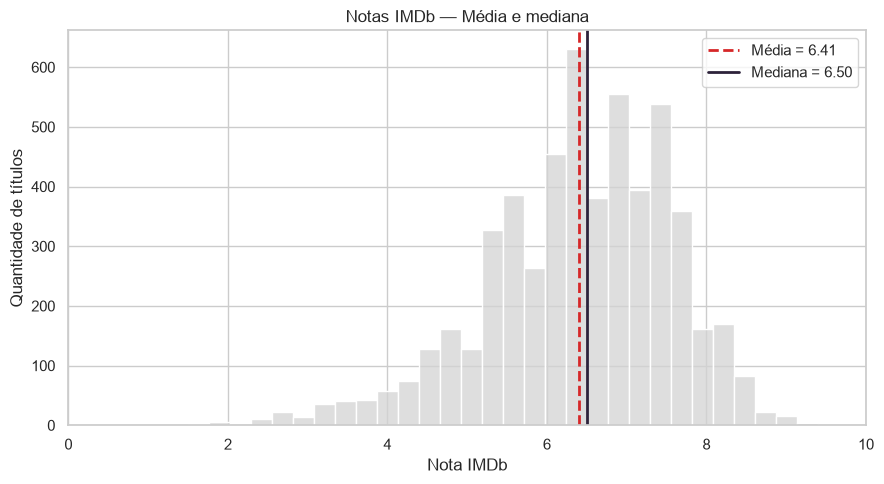

In [18]:
media_imdb = df["imdb_rating"].mean()
mediana_imdb = df["imdb_rating"].median()

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="imdb_rating",
    bins=30,
    color=COR_NEUTRA
)

plt.axvline(
    media_imdb,
    color=COR_ALERTA,
    linestyle="--",
    linewidth=2,
    label=f"Média = {media_imdb:.2f}"
)

plt.axvline(
    mediana_imdb,
    color=COR_DESTAQUE,
    linestyle="-",
    linewidth=2,
    label=f"Mediana = {mediana_imdb:.2f}"
)

plt.title("Notas IMDb — Média e mediana")
plt.xlabel("Nota IMDb")
plt.ylabel("Quantidade de títulos")
plt.xlim(0, 10)
plt.legend()
plt.tight_layout()
plt.show()

### Dispersão

In [19]:

dispersao = df[VARS_QUANT].agg(["var", "std"]).T

dispersao["IQR"] = (
    df[VARS_QUANT].quantile(0.75)
    - df[VARS_QUANT].quantile(0.25)
)

dispersao = dispersao.rename(columns={
    "var": "Variância",
    "std": "Desvio-padrão"
})

dispersao.round(2)

,Variância,Desvio-padrão,IQR
release_year,7.670000e+01,8.76,5.00
imdb_rating,1.350000e+00,1.16,1.50
imdb_votes,1.785361e+10,133617.42,14342.00
tmdb_rating,2.080000e+00,1.44,1.39
tmdb_popularity,3.376000e+01,5.81,3.52


Para discutir: o que o desvio-padrão e o IQR revelam sobre a dispersão das variáveis? Há indícios de influência de valores extremos?

As variáveis imdb_votes e tmdb_popularity apresentam desvios-padrão elevados em relação às respectivas médias, indicando grande variabilidade. Isso é compatível com a presença de poucos títulos com valores muito altos, observada nas etapas anteriores. O IQR complementa essa análise ao representar a dispersão dos 50% centrais, sendo menos sensível aos extremos. As notas IMDb estão mais concentradas em torno dos valores centrais, embora também apresentem variação.

## 4. Tratamento de Dados Ausentes e Outliers

Após examinar as distribuições, investigaremos os valores extremos e definiremos como lidar com as informações ausentes. As decisões considerarão as características de cada variável e os padrões encontrados nas etapas anteriores.

### Detecção de Outliers por IQR

A regra clássica marca como outlier qualquer ponto fora de `[Q1 - 1.5*IQR, Q3 + 1.5*IQR]`.

In [20]:
def limites_iqr(serie):
    q1 = serie.quantile(0.25)
    q3 = serie.quantile(0.75)
    iqr = q3 - q1

    return q1 - 1.5 * iqr, q3 + 1.5 * iqr


resumo_outliers = []

for coluna in VARS_QUANT:
    valores = df[coluna].dropna()

    limite_inferior, limite_superior = limites_iqr(valores)

    outliers = (
        (valores < limite_inferior)
        | (valores > limite_superior)
    )

    resumo_outliers.append({
        "Variável": coluna,
        "Limite inferior": limite_inferior,
        "Limite superior": limite_superior,
        "Quantidade de outliers": outliers.sum(),
        "Percentual (%)": outliers.mean() * 100
    })

pd.DataFrame(resumo_outliers).set_index("Variável").round(2)

,Limite inferior,Limite superior,Quantidade de outliers,Percentual (%)
Variável,,,,
release_year,2005.50,2025.50,745,9.57
imdb_rating,3.45,9.45,99,1.81
imdb_votes,-20965.50,36402.50,900,16.48
tmdb_rating,3.64,9.19,234,4.37
tmdb_popularity,-4.11,9.97,388,7.25


Utilizamos a regra do IQR para sinalizar valores abaixo de Q1 − 1,5 × IQR ou acima de Q3 + 1,5 × IQR. Esses limites são estatísticos e não representam, necessariamente, limites válidos do domínio.

Por exemplo, um ano de lançamento antigo ou uma quantidade muito alta de votos pode representar uma informação legítima. Da mesma forma, um limite inferior negativo calculado para votos não significa que votos negativos sejam possíveis. Por isso, os registros sinalizados precisam ser investigados antes de qualquer tratamento.

### Visualizando os Outliers

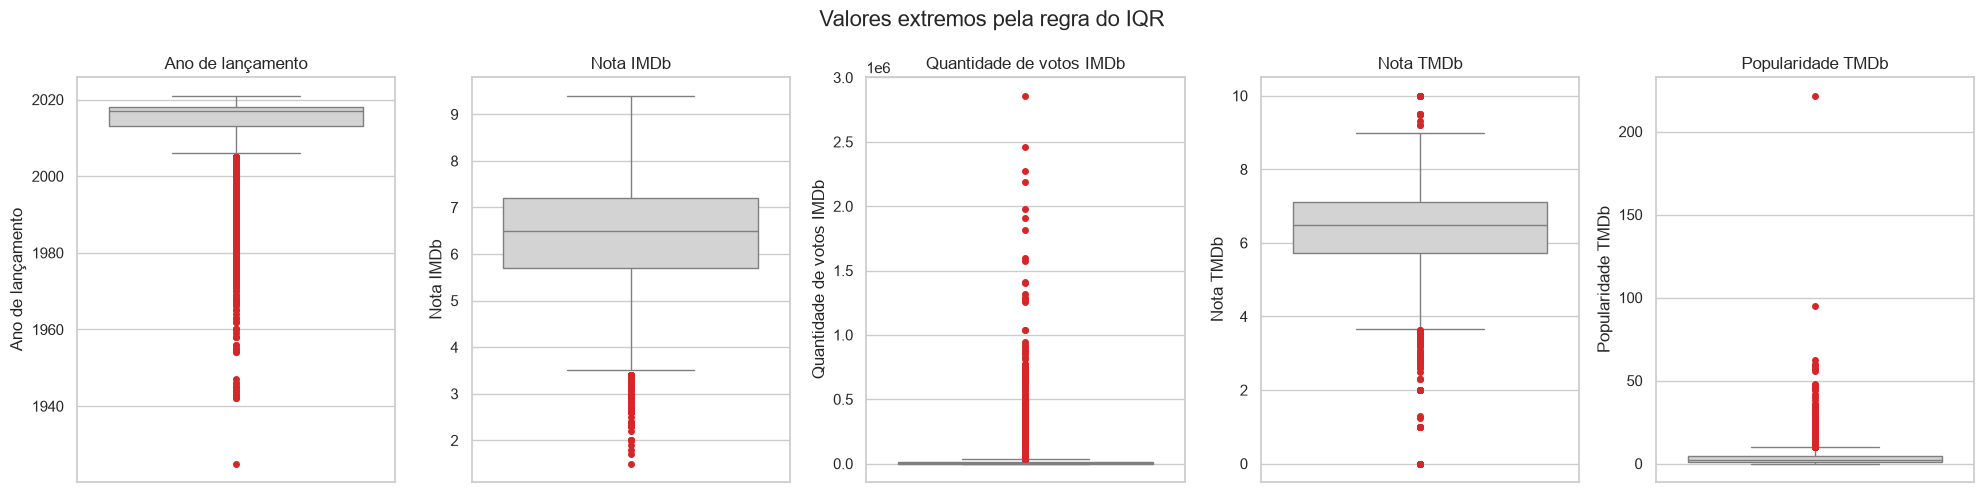

In [21]:
fig, axes = plt.subplots(
    1, len(VARS_QUANT),
    figsize=(20, 5)
)

for i, coluna in enumerate(VARS_QUANT):
    sns.boxplot(
        data=df,
        y=coluna,
        color=COR_NEUTRA,
        flierprops={
            "marker": "o",
            "markerfacecolor": COR_ALERTA,
            "markeredgecolor": COR_ALERTA,
            "markersize": 4
        },
        ax=axes[i]
    )

    axes[i].set_title(nomes_variaveis[coluna])
    axes[i].set_ylabel(nomes_variaveis[coluna])

fig.suptitle(
    "Valores extremos pela regra do IQR",
    fontsize=16
)

plt.tight_layout()
plt.show()

Para discutir: os valores extremos encontrados parecem registros legítimos, violações das regras do domínio ou possíveis erros de dados? Devemos mantê-los, investigá-los ou removê-los?

Valores muito altos de votos IMDb e popularidade TMDb podem representar títulos que receberam mais atenção. Anos de lançamento muito antigos também podem ser legítimos. Portanto, esses valores não devem ser removidos apenas por serem sinalizados pela regra do IQR.

Nas avaliações, uma nota baixa pode ser estatisticamente atípica sem representar erro. Entretanto, notas TMDb iguais a zero precisam ser investigadas para verificar se representam avaliações efetivas ou ausência de avaliação registrada como zero. Também é necessário considerar possíveis erros de correspondência entre títulos das diferentes fontes.

Por enquanto, manteremos os valores originais. A regra do IQR será utilizada para identificar registros que merecem atenção, sem realizar exclusões automáticas.

### Decidindo o Tratamento dos Dados Ausentes

A base apresenta uma quantidade expressiva de dados ausentes, especialmente nas informações de avaliações, popularidade e duração. Como essas ausências estão associadas a características dos registros, excluir todas as linhas incompletas poderia alterar a composição da base.

Optamos por preservar os registros e não preencher notas, votos ou popularidade com zero, média ou mediana, pois isso introduziria valores não observados e poderia alterar as distribuições e relações investigadas.

Nas análises individuais, utilizaremos os valores disponíveis em cada variável. Nas comparações que exigem duas informações simultaneamente, selecionaremos apenas os títulos com ambas disponíveis, informando o tamanho do subconjunto. Essa estratégia aproveita os dados existentes, mas não elimina o possível viés associado às ausências.

In [22]:

df_antes = df.copy()


df_notas = df.dropna(
    subset=["imdb_rating", "tmdb_rating"]
).copy()

print(f"Títulos na base completa: {len(df)}")
print(f"Títulos com as duas notas: {len(df_notas)}")
print(
    "Títulos fora da comparação entre notas:",
    len(df) - len(df_notas)
)

Títulos na base completa: 7786
Títulos com as duas notas: 5331
Títulos fora da comparação entre notas: 2455


A base completa permanece com 7.786 títulos. Para comparar diretamente as notas IMDb e TMDb, utilizaremos um subconjunto com 5.331 títulos que possuem ambas as avaliações. Os outros 2.455 registros continuam disponíveis para análises que não dependam das duas notas simultaneamente.

### Decidindo o Tratamento dos Outliers

Os valores extremos identificados pela regra do IQR não serão removidos automaticamente. Quantidades elevadas de votos, popularidade alta e anos de lançamento antigos podem representar características legítimas dos títulos.

Como não confirmamos erros nesses registros, manteremos os valores originais. Para explorar a forte assimetria de imdb_votes, criaremos uma versão transformada por logaritmo. Essa transformação comprime a escala, reduzindo a distância entre valores muito altos e os demais, sem excluir observações.

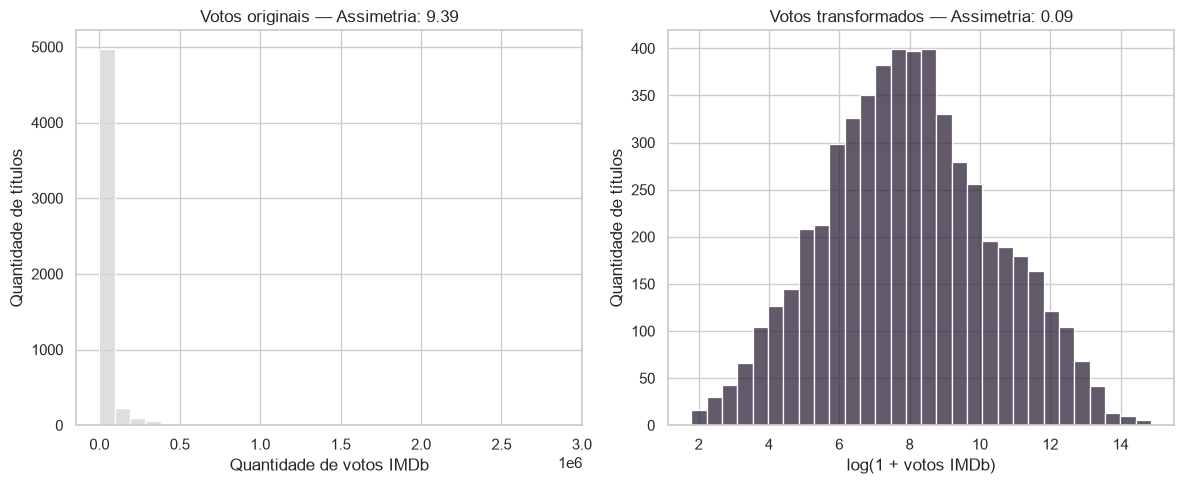

In [23]:

df["imdb_votes_log"] = np.log1p(df["imdb_votes"])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.histplot(
    data=df,
    x="imdb_votes",
    bins=30,
    color=COR_NEUTRA,
    ax=axes[0]
)

axes[0].set_title(
    f"Votos originais — Assimetria: {df['imdb_votes'].skew():.2f}"
)
axes[0].set_xlabel("Quantidade de votos IMDb")
axes[0].set_ylabel("Quantidade de títulos")

sns.histplot(
    data=df,
    x="imdb_votes_log",
    bins=30,
    color=COR_DESTAQUE,
    ax=axes[1]
)

axes[1].set_title(
    f"Votos transformados — Assimetria: "
    f"{df['imdb_votes_log'].skew():.2f}"
)
axes[1].set_xlabel("log(1 + votos IMDb)")
axes[1].set_ylabel("Quantidade de títulos")

plt.tight_layout()
plt.show()

Para discutir: a transformação logarítmica reduziu a assimetria dos votos IMDb? Como ela alterou a visualização da distribuição? A transformação altera a escala dos valores, mas não elimina os títulos com muitos votos nem comprova normalidade. A coluna transformada será mantida como demonstração; as próximas estatísticas das variáveis originais continuarão utilizando imdb_votes.

## 5. Estatística Descritiva pt 2

Após investigar as ausências e os outliers, decidimos preservar os registros e os valores originais. Criamos um subconjunto para futuras comparações entre notas e uma coluna logarítmica para explorar os votos IMDb. Agora verificaremos se as estatísticas das variáveis originais permaneceram iguais.

In [24]:
desc_depois = df[VARS_QUANT].describe().T

desc_depois["skewness"] = df[VARS_QUANT].skew()
desc_depois["kurtosis"] = df[VARS_QUANT].kurtosis()

desc_depois[[
    "count", "mean", "50%", "std",
    "min", "max", "skewness", "kurtosis"
]].rename(
    columns={"50%": "median"}
).round(2)

,count,mean,median,std,min,max,skewness,kurtosis
release_year,7786.0,2013.93,2017.00,8.76,1925.00,2021.00,-3.62,17.56
imdb_rating,5460.0,6.41,6.50,1.16,1.50,9.40,-0.67,0.61
imdb_votes,5460.0,36820.77,2771.00,133617.42,5.00,2858413.00,9.39,127.14
tmdb_rating,5355.0,6.26,6.47,1.44,0.00,10.00,-1.90,6.12
tmdb_popularity,5355.0,3.86,2.11,5.81,0.01,221.58,13.13,393.95


### Comparando "antes"x "depois""



In [25]:
comparacao = pd.DataFrame({
    "Média antes": df_antes[VARS_QUANT].mean(),
    "Média depois": df[VARS_QUANT].mean(),
    "Mediana antes": df_antes[VARS_QUANT].median(),
    "Mediana depois": df[VARS_QUANT].median(),
    "Desvio-padrão antes": df_antes[VARS_QUANT].std(),
    "Desvio-padrão depois": df[VARS_QUANT].std()
})

comparacao.round(2)

,Média antes,Média depois,Mediana antes,Mediana depois,Desvio-padrão antes,Desvio-padrão depois
release_year,2013.93,2013.93,2017.00,2017.00,8.76,8.76
imdb_rating,6.41,6.41,6.50,6.50,1.16,1.16
imdb_votes,36820.77,36820.77,2771.00,2771.00,133617.42,133617.42
tmdb_rating,6.26,6.26,6.47,6.47,1.44,1.44
tmdb_popularity,3.86,3.86,2.11,2.11,5.81,5.81


Para discutir: as curvas antes e depois se sobrepõem? Esse resultado é coerente com as decisões tomadas?

As curvas se sobrepõem completamente porque os valores das notas IMDb e TMDb permaneceram iguais. Não removemos registros da base principal nem preenchemos avaliações ausentes.

A criação do subconjunto df_notas e da coluna imdb_votes_log não alterou essas variáveis. Portanto, o gráfico confirma a preservação das distribuições originais. Isso não significa que as ausências foram resolvidas; elas continuam sendo consideradas como uma limitação das análises.

As notas IMDb ainda rejeitam normalidade?

Repetiremos o teste de Shapiro-Wilk com o mesmo procedimento de amostragem utilizado anteriormente. Como preservamos as notas originais, esperamos obter o mesmo resultado.

In [26]:

notas_antes = df_antes["imdb_rating"].dropna()
notas_depois = df["imdb_rating"].dropna()

amostra_antes = notas_antes.sample(
    n=min(5000, len(notas_antes)),
    random_state=42
)

amostra_depois = notas_depois.sample(
    n=min(5000, len(notas_depois)),
    random_state=42
)

w_antes, p_antes = stats.shapiro(amostra_antes)
w_depois, p_depois = stats.shapiro(amostra_depois)

print(f"Antes:  W = {w_antes:.4f} | p-valor = {p_antes:.4g}")
print(f"Depois: W = {w_depois:.4f} | p-valor = {p_depois:.4g}")

Antes:  W = 0.9731 | p-valor = 1.166e-29
Depois: W = 0.9731 | p-valor = 1.166e-29


O teste apresentou o mesmo resultado antes e depois: W ≈ 0,9731 e p ≈ 1,17 × 10⁻²⁹. Como o p-valor permanece abaixo de 0,05, continuamos rejeitando a hipótese de normalidade.

A igualdade dos resultados é esperada, pois utilizamos as mesmas notas e o mesmo procedimento de amostragem. Essa repetição confirma a preservação dos dados; não representa uma nova evidência independente contra a normalidade.

**Visualizando antes x depois, lado a lado**

Compararemos as distribuições das notas IMDb e TMDb antes e depois das decisões de tratamento. Como preservamos os registros e os valores originais, esperamos que as curvas se sobreponham completamente.

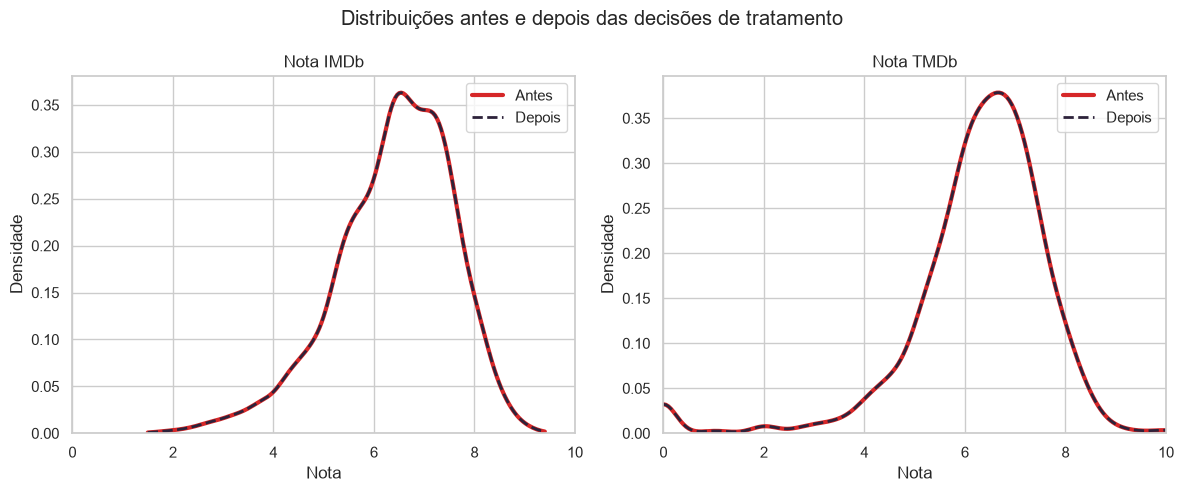

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, coluna in zip(axes, ["imdb_rating", "tmdb_rating"]):
    sns.kdeplot(
        x=df_antes[coluna].dropna(),
        color=COR_ALERTA,
        linewidth=3,
        label="Antes",
        cut=0,
        ax=ax
    )

    sns.kdeplot(
        x=df[coluna].dropna(),
        color=COR_DESTAQUE,
        linestyle="--",
        linewidth=2,
        label="Depois",
        cut=0,
        ax=ax
    )

    ax.set_title(nomes_variaveis[coluna])
    ax.set_xlabel("Nota")
    ax.set_ylabel("Densidade")
    ax.set_xlim(0, 10)
    ax.legend()

fig.suptitle("Distribuições antes e depois das decisões de tratamento")
plt.tight_layout()
plt.show()

Pra discutir: as curvas “antes” e “depois” se sobrepõem? Isso é esperado considerando que preservamos os registros, mantivemos os outliers e não preenchemos os valores ausentes?

Resposta: Sim, as curvas se sobrepõem completamente porque as notas IMDb e TMDb não foram alteradas. Diferentemente do exemplo da aula, não removemos nenhuma linha da base principal.

Essa comparação confirma que nossas decisões preservaram as distribuições originais. Caso tivéssemos removido registros, preenchido ausências ou alterado valores extremos, as curvas poderiam apresentar diferenças, dependendo da quantidade e das características dos dados afetados.

Portanto, a comparação “antes × depois” verifica o efeito das decisões tomadas, em vez de pressupor seu resultado. A sobreposição, neste caso, não significa que os problemas da base foram resolvidos, mas que os valores observados foram preservados.

## 6. Princípio Relacional

### Análise de Variáveis Qualitativas

Analisaremos a distribuição dos títulos por tipo de conteúdo, classificação indicativa, gênero principal e país principal. As frequências permitirão identificar categorias predominantes e grupos pouco representados, orientando as próximas comparações.

#### Frequências absolutas e relativas

In [28]:
VARS_QUALI = [
    "tipo_conteudo",
    "rating",
    "primary_genre",
    "primary_country"
]

for coluna in VARS_QUALI:

    categorias = df[coluna].fillna("Não informado")

    frequencia_absoluta = categorias.value_counts()
    frequencia_relativa = categorias.value_counts(
        normalize=True
    ) * 100

    tabela = pd.DataFrame({
        "Quantidade": frequencia_absoluta,
        "Percentual (%)": frequencia_relativa
    })

    print(f"\nFrequências — {coluna}")
    display(tabela.round(2))


Frequências — tipo_conteudo


,Quantidade,Percentual (%)
tipo_conteudo,,
Filme,5376,69.05
Série,2410,30.95



Frequências — rating


,Quantidade,Percentual (%)
rating,,
TV-MA,2862,36.76
TV-14,1931,24.80
TV-PG,806,10.35
R,665,8.54
PG-13,386,4.96
TV-Y,280,3.60
TV-Y7,271,3.48
PG,247,3.17
TV-G,194,2.49



Frequências — primary_genre


,Quantidade,Percentual (%)
primary_genre,,
Dramas,1383,17.76
Comedies,1074,13.79
Documentary,945,12.14
Action & Adventure,721,9.26
International TV Shows,690,8.86
Children & Family Movies,502,6.45
Crime TV Shows,369,4.74
Kids,359,4.61
Stand-Up Comedy,321,4.12



Frequências — primary_country


,Quantidade,Percentual (%)
primary_country,,
United States,2883,37.03
India,956,12.28
United Kingdom,577,7.41
Não informado,507,6.51
Canada,259,3.33
...,...,...
Zimbabwe,1,0.01
Iran,1,0.01
Mauritius,1,0.01


#### Visualizando as frequências

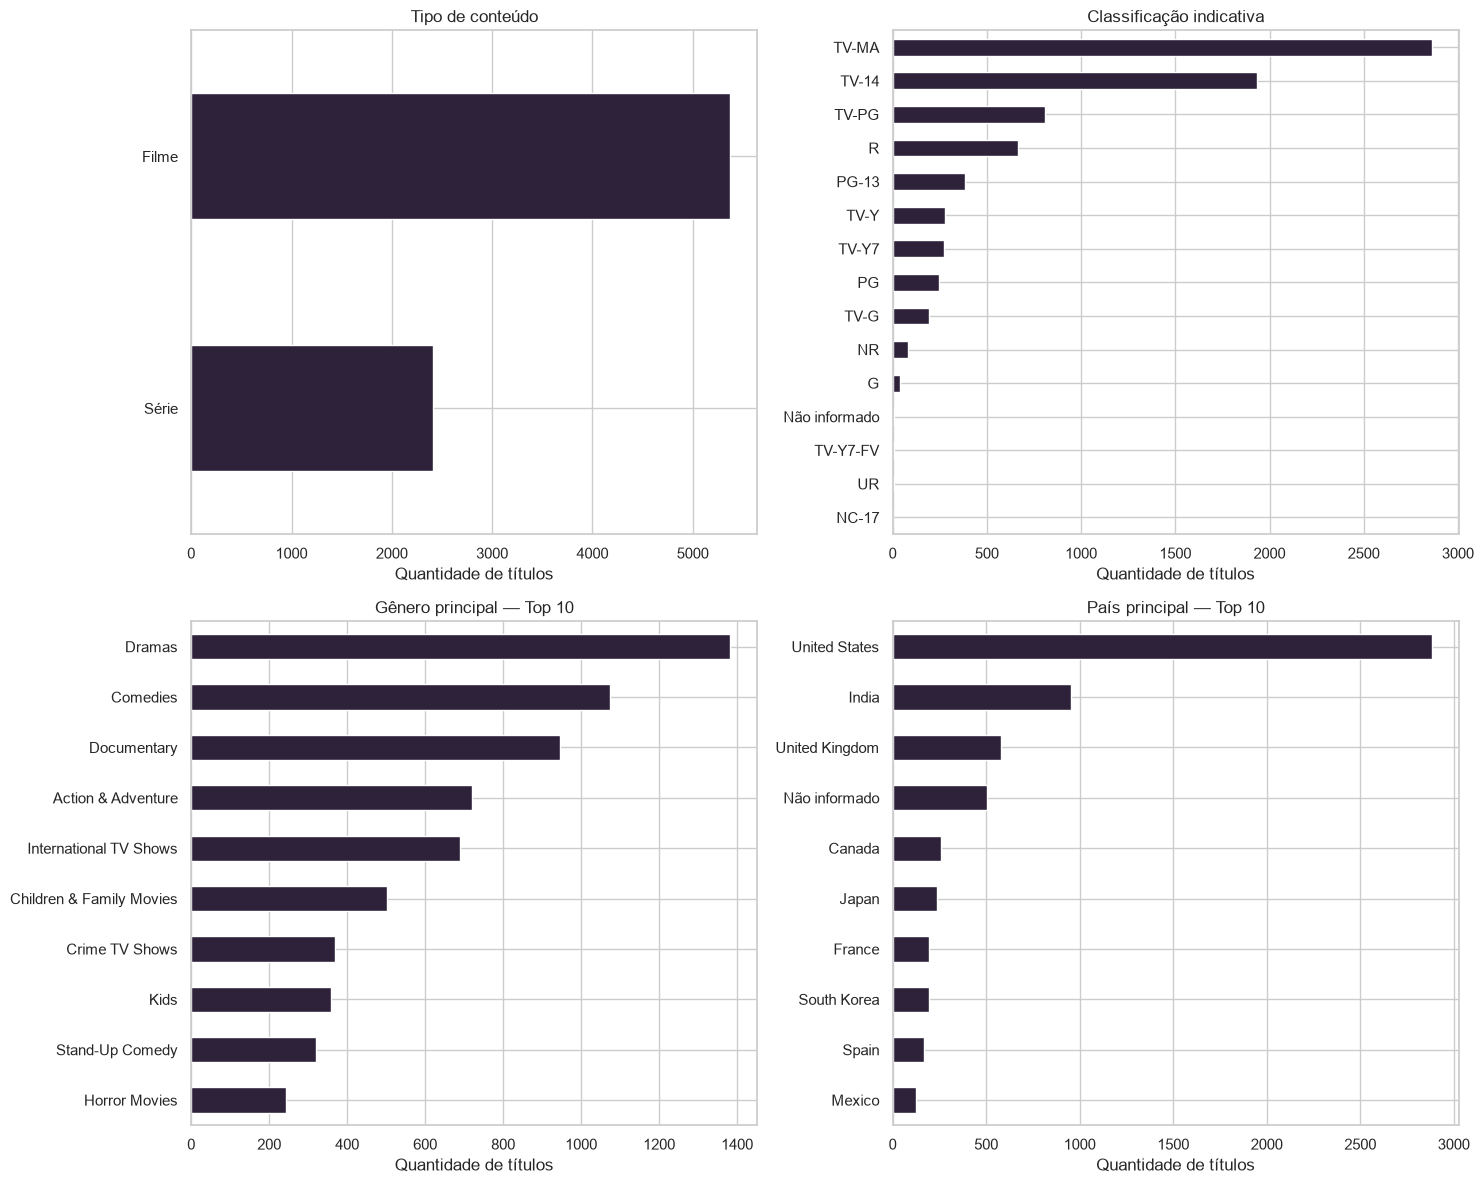

In [29]:
titulos = {
    "tipo_conteudo": "Tipo de conteúdo",
    "rating": "Classificação indicativa",
    "primary_genre": "Gênero principal — Top 10",
    "primary_country": "País principal — Top 10"
}

fig, axes = plt.subplots(2, 2, figsize=(15, 12))
axes = axes.ravel()

for i, coluna in enumerate(VARS_QUALI):
    contagens = df[coluna].fillna("Não informado").value_counts()


    if coluna in ["primary_genre", "primary_country"]:
        contagens = contagens.head(10)

    contagens = contagens.sort_values()

    contagens.plot(
        kind="barh",
        color=COR_DESTAQUE,
        ax=axes[i]
    )

    axes[i].set_title(titulos[coluna])
    axes[i].set_xlabel("Quantidade de títulos")
    axes[i].set_ylabel("")

plt.tight_layout()
plt.show()

Para discutir: alguma variável qualitativa apresenta forte concentração em poucas categorias? Como essa distribuição pode afetar as comparações entre grupos?

A distribuição entre filmes e séries é desigual: filmes representam aproximadamente 69% dos títulos, enquanto séries correspondem a 31%. Há predominância de filmes, mas as duas categorias possuem participação expressiva na base.

Nas outras variáveis, as categorias mais frequentes incluem TV-MA na classificação indicativa, Dramas no gênero principal e United States no país principal. Entretanto, ser a categoria mais frequente não significa, por si só, concentrar quase todas as observações.

Essas diferenças de tamanho precisam ser consideradas nas análises seguintes. Comparações de quantidades absolutas podem destacar grupos maiores simplesmente porque possuem mais títulos. Por isso, quando o objetivo for comparar características entre grupos, utilizaremos também proporções e informaremos o número de registros disponíveis.

#### Desbalanceamento entre Classes

Avaliaremos o desbalanceamento das variáveis qualitativas utilizando duas medidas:

Razão de desbalanceamento: quantidade da categoria mais frequente dividida pela quantidade da menos frequente. Um resultado igual a 1 indica quantidades iguais; valores maiores indicam desigualdade.
Entropia de Shannon normalizada: varia de 0 a 1. Valores próximos de 1 indicam distribuição mais equilibrada; valores próximos de 0 indicam concentração em poucas categorias.

Incluiremos as ausências como “Não informado”, mantendo o mesmo critério das tabelas de frequência.

In [30]:
from scipy.stats import entropy

def metrica_desbalanceamento(serie):
    contagens = serie.fillna("Não informado").value_counts()

    contagens = contagens[contagens > 0]

    proporcoes = contagens / contagens.sum()
    n_categorias = len(contagens)

    razao = contagens.max() / contagens.min()

    if n_categorias > 1:
        entropia_normalizada = (
            entropy(proporcoes, base=2)
            / np.log2(n_categorias)
        )
    else:
        entropia_normalizada = 0.0

    return pd.Series({
        "Número de categorias": n_categorias,
        "Razão de desbalanceamento": razao,
        "Entropia normalizada": entropia_normalizada
    })

resultado_desbalanceamento = pd.DataFrame({
    coluna: metrica_desbalanceamento(df[coluna])
    for coluna in VARS_QUALI
}).T

resultado_desbalanceamento.round(3)

,Número de categorias,Razão de desbalanceamento,Entropia normalizada
tipo_conteudo,2.0,2.231,0.893
rating,15.0,954.000,0.680
primary_genre,35.0,1383.000,0.748
primary_country,81.0,2883.000,0.602


Para discutir: quais variáveis apresentam maior desigualdade entre categorias? A distribuição entre filmes e séries é muito desbalanceada? As duas medidas levam à mesma interpretação?

A razão de desbalanceamento é aproximadamente 2,23, indicando que existem cerca de 2,23 filmes para cada série. A entropia normalizada é aproximadamente 0,89, mostrando que, apesar da predominância de filmes, a distribuição não está próxima de uma concentração total em uma única categoria.

As duas medidas são complementares: a razão compara somente as categorias mais e menos frequentes, enquanto a entropia considera a distribuição completa. Em variáveis com muitas categorias, uma categoria muito rara pode produzir uma razão elevada sem que uma única categoria domine a base.

### Análise Bivariada

Investigaremos as relações entre ano de lançamento, notas IMDb e TMDb, quantidade de votos e popularidade. A correlação indica a direção e a intensidade de uma associação, mas não demonstra causalidade.

#### Quantitativa x Quantitativa - Correlação

Compararemos três medidas:

Pearson: mede associações lineares e pode ser bastante influenciado por valores extremos.
Spearman: utiliza a ordenação dos valores para medir associações monotônicas — quando uma variável tende a aumentar ou diminuir conforme a outra aumenta.
Kendall: também utiliza ordenações, considerando a concordância entre pares de observações.

Como votos e popularidade apresentam forte assimetria e valores extremos, daremos atenção especial a Spearman, comparando seus resultados com os demais métodos.

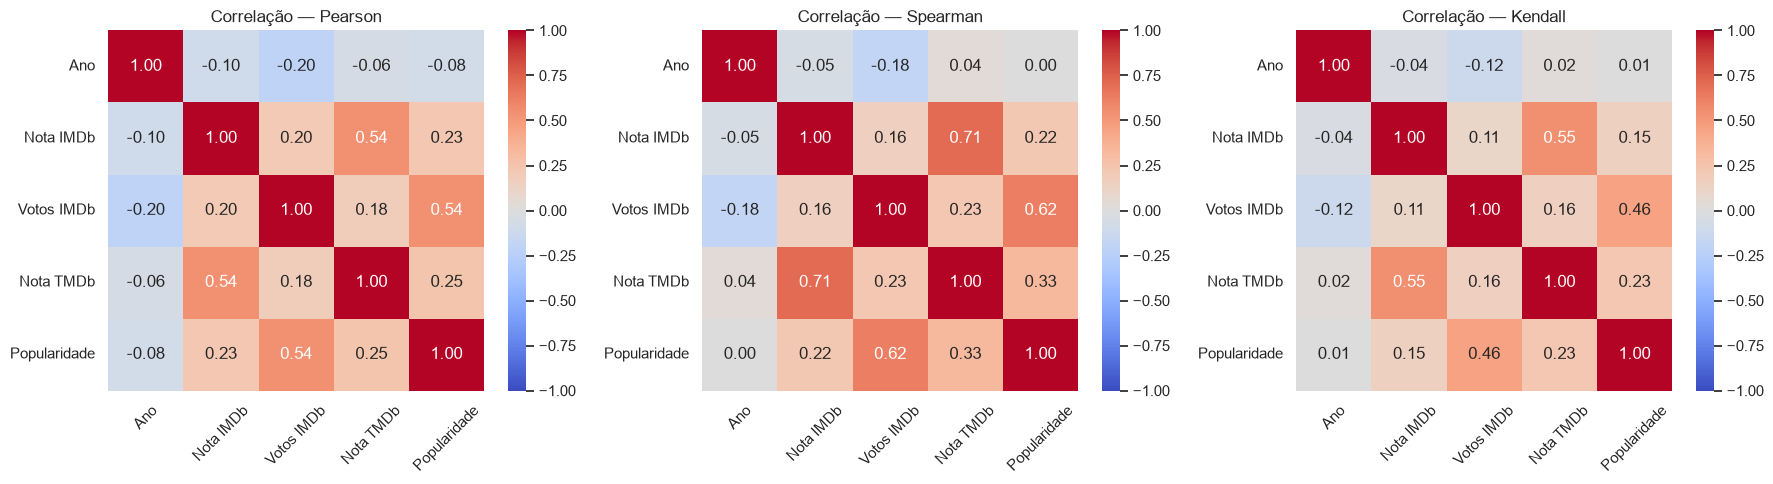

In [31]:
metodos = ["pearson", "spearman", "kendall"]

rotulos = [
    "Ano",
    "Nota IMDb",
    "Votos IMDb",
    "Nota TMDb",
    "Popularidade"
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, metodo in zip(axes, metodos):
    matriz = df[VARS_QUANT].corr(method=metodo)

    sns.heatmap(
        matriz,
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        vmin=-1,
        vmax=1,
        center=0,
        xticklabels=rotulos,
        yticklabels=rotulos,
        ax=ax
    )

    ax.set_title(f"Correlação — {metodo.capitalize()}")
    ax.tick_params(axis="x", rotation=45)
    ax.tick_params(axis="y", rotation=0)

plt.tight_layout()
plt.show()

In [32]:
disponiveis = df[VARS_QUANT].notna().astype(int)

quantidade_por_par = disponiveis.T.dot(disponiveis)

quantidade_por_par

,release_year,imdb_rating,imdb_votes,tmdb_rating,tmdb_popularity
release_year,7786,5460,5460,5355,5355
imdb_rating,5460,5460,5460,5331,5331
imdb_votes,5460,5460,5460,5331,5331
tmdb_rating,5355,5331,5331,5355,5355
tmdb_popularity,5355,5331,5331,5355,5355


Como os dados do triângulo superior e inferior são simétricos, poderíamos plotar a matriz de correlação da seguinte forma.

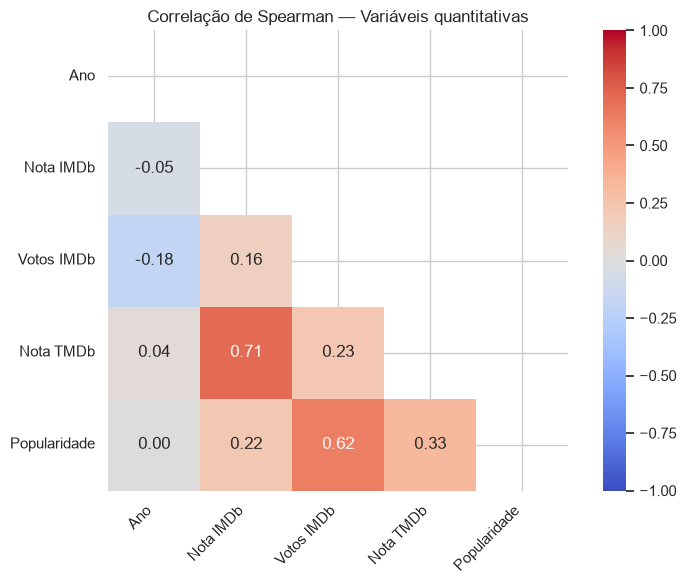

In [33]:
corr_spearman = df[VARS_QUANT].corr(method="spearman")


mascara = np.triu(
    np.ones_like(corr_spearman, dtype=bool)
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    corr_spearman,
    mask=mascara,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    xticklabels=rotulos,
    yticklabels=rotulos
)

plt.title("Correlação de Spearman — Variáveis quantitativas")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

A matriz triangular apresenta as mesmas correlações de Spearman mostradas anteriormente, sem repetir os pares de variáveis. A diagonal também foi ocultada, pois a correlação de uma variável consigo mesma é sempre igual a 1. Essa organização facilita a leitura sem alterar os resultados.

**Pra discutir:** Pearson e Spearman divergem bastante em algum par de variáveis? Se sim, isso é um sinal de relação não-linear (monotônica, mas não em linha reta) em que Spearman capturaria e Pearson não.

In [34]:
corr_pearson = df[VARS_QUANT].corr(method="pearson")
corr_spearman = df[VARS_QUANT].corr(method="spearman")

comparacoes = []

for i, primeira in enumerate(VARS_QUANT):
    for segunda in VARS_QUANT[i + 1:]:
        pearson = corr_pearson.loc[primeira, segunda]
        spearman = corr_spearman.loc[primeira, segunda]

        comparacoes.append({
            "Variável 1": primeira,
            "Variável 2": segunda,
            "Pearson": pearson,
            "Spearman": spearman,
            "Diferença absoluta": abs(pearson - spearman)
        })

pd.DataFrame(comparacoes).sort_values(
    "Diferença absoluta",
    ascending=False
).round(3)

,Variável 1,Variável 2,Pearson,Spearman,Diferença absoluta
5,imdb_rating,tmdb_rating,0.542,0.709,0.166
2,release_year,tmdb_rating,-0.060,0.035,0.095
3,release_year,tmdb_popularity,-0.081,0.000,0.081
8,imdb_votes,tmdb_popularity,0.540,0.620,0.080
9,tmdb_rating,tmdb_popularity,0.249,0.327,0.078
7,imdb_votes,tmdb_rating,0.176,0.233,0.057
4,imdb_rating,imdb_votes,0.205,0.159,0.045
0,release_year,imdb_rating,-0.095,-0.052,0.043
1,release_year,imdb_votes,-0.204,-0.180,0.024
6,imdb_rating,tmdb_popularity,0.233,0.225,0.008


#### Dispersão (scatter) entre duas variáveis quantitativas

Selecionamos as notas IMDb e TMDb porque ambas representam avaliações dos títulos, permitindo investigar se notas maiores em uma plataforma tendem a acompanhar notas maiores na outra. Utilizaremos somente os registros com ambas as notas disponíveis e diferenciaremos filmes e séries pelas cores.

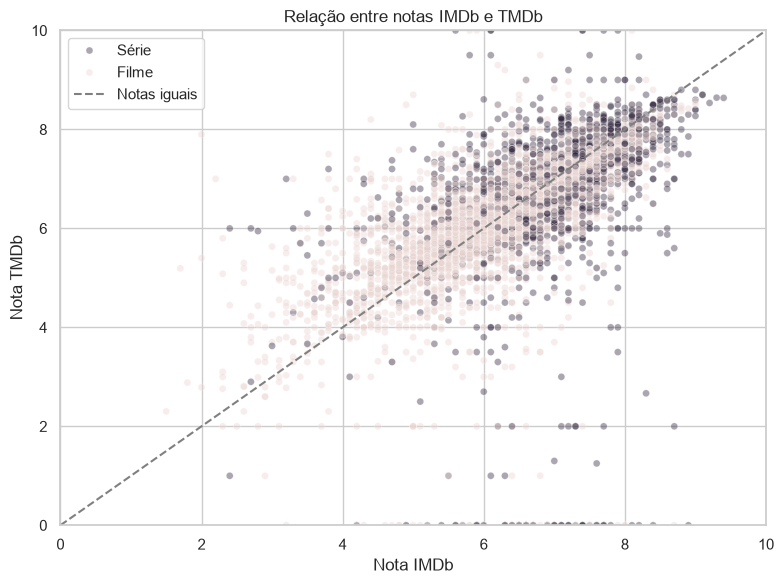

In [35]:
df_notas = df.dropna(
    subset=["imdb_rating", "tmdb_rating"]
).copy()

plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df_notas,
    x="imdb_rating",
    y="tmdb_rating",
    hue="tipo_conteudo",
    palette={
        "Filme": COR_CONTEXTO,
        "Série": COR_DESTAQUE
    },
    alpha=0.4,
    s=25
)

plt.plot(
    [0, 10], [0, 10],
    color="gray",
    linestyle="--",
    label="Notas iguais"
)

plt.title("Relação entre notas IMDb e TMDb")
plt.xlabel("Nota IMDb")
plt.ylabel("Nota TMDb")
plt.xlim(0, 10)
plt.ylim(0, 10)
plt.legend()
plt.tight_layout()
plt.show()

Para discutir: notas maiores no IMDb tendem a acompanhar notas maiores no TMDb? Filmes e séries ocupam regiões diferentes do gráfico ou se sobrepõem? Existem títulos com avaliações muito diferentes entre as plataformas?
Existe uma associação positiva: títulos com notas maiores no IMDb tendem a apresentar notas maiores no TMDb, embora essa relação não seja perfeita. Filmes e séries apresentam sobreposição nas faixas de avaliação, mas as séries tendem a ter notas mais altas.

Também existem títulos com avaliações bastante diferentes entre as plataformas, representados pelos pontos afastados da linha de igualdade. Essas diferenças podem estar relacionadas ao público avaliador ou a problemas de correspondência entre os títulos, exigindo investigação. A associação não significa que as plataformas atribuam notas iguais, e a análise considera apenas os registros com ambas as avaliações disponíveis.

#### Quantitativa x Qualitativa: Comparando Grupos

Compararemos as avaliações de filmes e séries utilizando dois testes: o teste t de Welch, que compara médias sem exigir variâncias iguais, e o Mann-Whitney, que compara as distribuições por meio da ordenação dos valores.

Os testes respondem a perguntas diferentes. O Mann-Whitney não deve ser interpretado automaticamente como um teste de medianas quando os grupos apresentam distribuições com formatos diferentes. Além disso, a rejeição da normalidade na base inteira não determina, sozinha, qual teste devemos utilizar na comparação entre grupos.

In [36]:
resultados_comparacao = []

for coluna in ["imdb_rating", "tmdb_rating"]:
    filmes = df.loc[
        df["tipo_conteudo"] == "Filme", coluna
    ].dropna()

    series = df.loc[
        df["tipo_conteudo"] == "Série", coluna
    ].dropna()

    stat_t, p_t = stats.ttest_ind(
        filmes,
        series,
        equal_var=False
    )

    stat_u, p_u = stats.mannwhitneyu(
        filmes,
        series,
        alternative="two-sided",
        method="asymptotic"
    )

    resultados_comparacao.append({
        "Variável": coluna,
        "N filmes": len(filmes),
        "N séries": len(series),
        "Média filmes": filmes.mean(),
        "Média séries": series.mean(),
        "Mediana filmes": filmes.median(),
        "Mediana séries": series.median(),
        "P-valor Welch": p_t,
        "P-valor Mann-Whitney": p_u,
        "Concordam em 5%?": (
            "Sim" if (p_t < 0.05) == (p_u < 0.05)
            else "Não"
        )
    })

tabela_comparacao = pd.DataFrame(
    resultados_comparacao
).set_index("Variável")

tabela_comparacao.style.format({
    "Média filmes": "{:.2f}",
    "Média séries": "{:.2f}",
    "Mediana filmes": "{:.2f}",
    "Mediana séries": "{:.2f}",
    "P-valor Welch": "{:.3e}",
    "P-valor Mann-Whitney": "{:.3e}"
})

,N filmes,N séries,Média filmes,Média séries,Mediana filmes,Mediana séries,P-valor Welch,P-valor Mann-Whitney,Concordam em 5%?
Variável,,,,,,,,,
imdb_rating,3965,1495,6.21,6.94,6.30,7.10,5.177e-103,1.275e-107,Sim
tmdb_rating,3939,1416,6.15,6.57,6.30,6.97,2.747e-15,6.765e-69,Sim


Para discutir: os testes concordam quanto à existência de diferenças entre filmes e séries? Como as médias e medianas ajudam a interpretar essas diferenças?

Os testes de Welch e Mann-Whitney concordam quanto à existência de diferenças entre filmes e séries nas duas plataformas, apresentando p-valores inferiores a 0,05. Welch indica diferença nas médias, enquanto Mann-Whitney aponta diferença nas distribuições.

As médias e medianas maiores nas séries mostram a direção dessa diferença: entre os títulos com avaliações disponíveis, as séries tendem a receber notas mais altas. Observar essas medidas permite avaliar o tamanho da diferença, pois o p-valor, sozinho, não informa sua importância prática.

Esses resultados se referem aos registros analisados e não demonstram que ser uma série seja a causa das avaliações mais altas.

Comparação entre três gêneros — ANOVA e Kruskal-Wallis

Compararemos as notas IMDb dos três gêneros principais mais frequentes entre os filmes com avaliação disponível. A ANOVA compara médias, enquanto o Kruskal-Wallis compara distribuições por postos. Utilizaremos somente filmes para evitar misturar diferenças de gênero com diferenças entre filmes e séries.

A ANOVA clássica pressupõe variâncias iguais e normalidade dos erros dentro dos grupos. Apresentaremos seus resultados como comparação exploratória, considerando também o Kruskal-Wallis e as estatísticas descritivas.

In [37]:
filmes_avaliados = df.loc[
    df["tipo_conteudo"] == "Filme"
].dropna(subset=["primary_genre", "imdb_rating"])

generos = (
    filmes_avaliados["primary_genre"]
    .value_counts()
    .head(3)
    .index
)

dados_generos = filmes_avaliados[
    filmes_avaliados["primary_genre"].isin(generos)
]

resumo = (
    dados_generos.groupby("primary_genre")["imdb_rating"]
    .agg(["count", "mean", "median", "std"])
    .reindex(generos)
)

display(resumo.round(2))

grupos = [
    dados_generos.loc[
        dados_generos["primary_genre"] == genero,
        "imdb_rating"
    ]
    for genero in generos
]

stat_anova, p_anova = stats.f_oneway(*grupos)
stat_kw, p_kw = stats.kruskal(*grupos)

print(f"ANOVA: F = {stat_anova:.3f} | p = {p_anova:.3e}")
print(f"Kruskal-Wallis: H = {stat_kw:.3f} | p = {p_kw:.3e}")

,count,mean,median,std
primary_genre,,,,
Dramas,1185,6.39,6.5,1.02
Comedies,890,5.93,6.0,1.13
Action & Adventure,621,6.03,6.2,1.17


ANOVA: F = 50.858 | p = 2.087e-22
Kruskal-Wallis: H = 103.249 | p = 3.799e-23


Para discutir: ANOVA e Kruskal-Wallis concordam quanto à existência de diferenças nas notas IMDb entre os gêneros selecionados? O que as médias e medianas mostram?

Na versão do CSV conferida, os gêneros selecionados foram Dramas, Comedies e Action & Adventure. Os dois testes apresentaram p-valores inferiores a 0,05, rejeitando suas respectivas hipóteses de igualdade entre os grupos.

Dramas apresentou a maior média e mediana, seguido de Action & Adventure e Comedies. Isso descreve diferenças nas avaliações típicas dos grupos, mas os testes globais não identificam quais pares diferem estatisticamente nem comprovam que todos os gêneros sejam diferentes entre si. Para isso, seriam necessárias comparações posteriores.

Esses resultados são exploratórios, restritos aos filmes com avaliações disponíveis, e não demonstram que o gênero cause a diferença nas notas.



#### Qualitativa × Qualitativa

Investigaremos se existe associação entre tipo de conteúdo e classificação indicativa. Utilizaremos uma tabela de contingência e o teste qui-quadrado de independência.

Manteremos as quatro classificações mais frequentes e agruparemos as demais em “Outras”, facilitando a leitura e reduzindo categorias com poucos registros. Os títulos sem classificação indicativa ficarão fora desta comparação.

classificacao_grupo,Outras,R,TV-14,TV-MA,TV-PG
tipo_conteudo,,,,,
Filme,1087,663,1272,1844,505
Série,428,2,659,1018,301


Qui-quadrado: 350.562
P-valor: 1.326e-74
Menor frequência esperada: 205.85


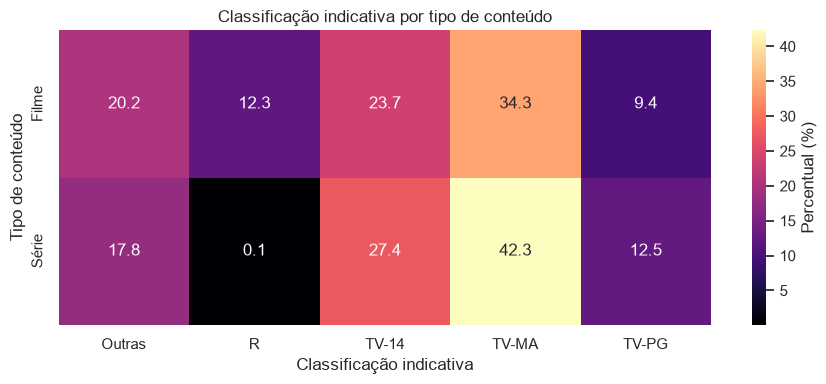

In [38]:
dados_classificacao = df.dropna(
    subset=["tipo_conteudo", "rating"]
).copy()

mais_frequentes = (
    dados_classificacao["rating"]
    .value_counts()
    .head(4)
    .index
)

dados_classificacao["classificacao_grupo"] = (
    dados_classificacao["rating"].where(
        dados_classificacao["rating"].isin(mais_frequentes),
        "Outras"
    )
)

contingencia = pd.crosstab(
    dados_classificacao["tipo_conteudo"],
    dados_classificacao["classificacao_grupo"]
)

chi2, p_valor, gl, esperadas = stats.chi2_contingency(
    contingencia
)

display(contingencia)

print(f"Qui-quadrado: {chi2:.3f}")
print(f"P-valor: {p_valor:.3e}")
print(f"Menor frequência esperada: {esperadas.min():.2f}")


percentuais = contingencia.div(
    contingencia.sum(axis=1), axis=0
) * 100

plt.figure(figsize=(9, 4))

sns.heatmap(
    percentuais,
    annot=True,
    fmt=".1f",
    cmap="magma",
    cbar_kws={"label": "Percentual (%)"}
)

plt.title("Classificação indicativa por tipo de conteúdo")
plt.xlabel("Classificação indicativa")
plt.ylabel("Tipo de conteúdo")
plt.tight_layout()
plt.show()

Para discutir: o teste qui-quadrado indica associação entre tipo de conteúdo e classificação indicativa? O que os percentuais mostram?

Na base conferida, o teste apresentou p-valor inferior a 0,05, indicando evidência contra a independência entre tipo de conteúdo e classificação indicativa. Portanto, a distribuição das classificações varia entre filmes e séries.

TV-MA tem participação proporcional maior nas séries, enquanto a classificação R aparece quase exclusivamente nos filmes. Essas diferenças devem ser interpretadas considerando que a base reúne sistemas de classificação distintos para cinema e televisão. Assim, a associação não demonstra que um tipo de conteúdo seja necessariamente mais adequado ou inadequado para determinada idade.

A conclusão se refere às categorias agrupadas nesta análise e aos títulos com classificação disponível. O grupo “Outras” reúne classificações diferentes, podendo ocultar particularidades.

#### Representatividade e disponibilidade de avaliações

Investigaremos se a disponibilidade de notas IMDb é semelhante entre filmes e séries. Diferenças nessa disponibilidade podem afetar as comparações, pois os títulos avaliados podem não representar igualmente os dois grupos.

Essa análise examina uma possível fonte de viés de seleção. Ela não constitui uma avaliação de justiça algorítmica, pois não estamos avaliando decisões de um modelo sobre grupos de pessoas.

,total_titulos,titulos_com_nota,percentual_com_nota
tipo_conteudo,,,
Filme,5376,3965,73.75
Série,2410,1495,62.03


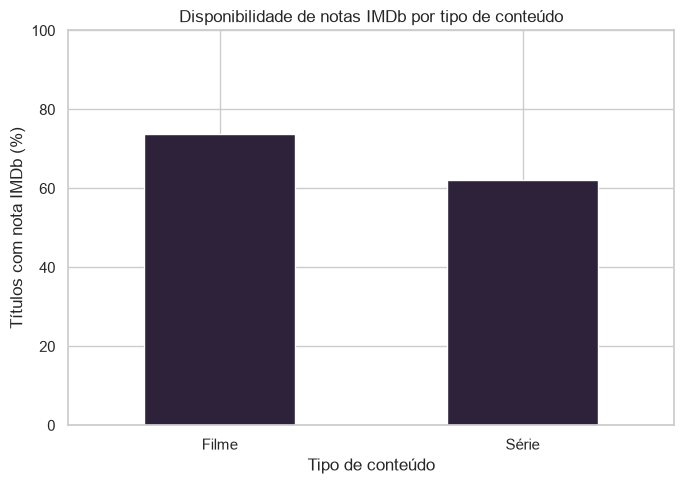

In [39]:
dados_cobertura = df.assign(
    nota_imdb_disponivel=df["imdb_rating"].notna()
)

cobertura = dados_cobertura.groupby("tipo_conteudo").agg(
    total_titulos=("nota_imdb_disponivel", "size"),
    titulos_com_nota=("nota_imdb_disponivel", "sum")
)

cobertura["percentual_com_nota"] = (
    cobertura["titulos_com_nota"]
    / cobertura["total_titulos"] * 100
)

display(cobertura.round(2))

ax = cobertura["percentual_com_nota"].plot(
    kind="bar",
    color=COR_DESTAQUE,
    figsize=(7, 5)
)

ax.set_title("Disponibilidade de notas IMDb por tipo de conteúdo")
ax.set_xlabel("Tipo de conteúdo")
ax.set_ylabel("Títulos com nota IMDb (%)")
ax.set_ylim(0, 100)
ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

Para discutir: a proporção de títulos com nota IMDb é semelhante entre filmes e séries? Como isso pode afetar a comparação das avaliações?

A disponibilidade de notas IMDb é diferente entre os grupos. Na base de 7.786 títulos utilizada no notebook, aproximadamente 73,75% dos filmes possuem nota, contra 62,03% das séries.

Isso significa que a comparação das avaliações utiliza uma parcela proporcionalmente menor das séries. Se os títulos sem nota tiverem características diferentes dos avaliados, as médias e distribuições observadas poderão apresentar viés de seleção. Portanto, as conclusões devem se limitar aos títulos com avaliações disponíveis. Essa diferença de cobertura não comprova discriminação nem permite determinar, sozinha, sua causa.

Qui-quadrado: 108.556
P-valor: 2.031e-25
Menor frequência esperada: 719.97


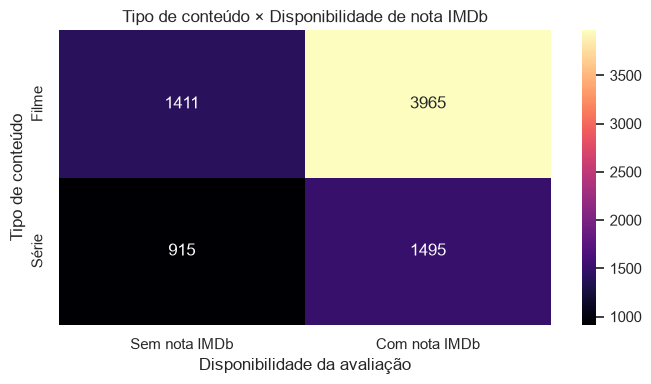

In [40]:

tabela_cobertura = pd.crosstab(
    df["tipo_conteudo"],
    df["imdb_rating"].notna()
).reindex(columns=[False, True], fill_value=0)

tabela_cobertura.columns = ["Sem nota IMDb", "Com nota IMDb"]


chi2, p_valor, gl, esperadas = stats.chi2_contingency(
    tabela_cobertura
)

print(f"Qui-quadrado: {chi2:.3f}")
print(f"P-valor: {p_valor:.3e}")
print(f"Menor frequência esperada: {esperadas.min():.2f}")

plt.figure(figsize=(7, 4))

sns.heatmap(
    tabela_cobertura,
    annot=True,
    fmt="d",
    cmap="magma"
)

plt.title("Tipo de conteúdo × Disponibilidade de nota IMDb")
plt.xlabel("Disponibilidade da avaliação")
plt.ylabel("Tipo de conteúdo")
plt.tight_layout()
plt.show()


Para discutir: o teste qui-quadrado indica associação entre tipo de conteúdo e disponibilidade de nota IMDb? Isso explica por que existem avaliações ausentes?

O teste apresenta p-valor inferior a 0,05, indicando evidência contra a independência entre tipo de conteúdo e disponibilidade de nota IMDb. Esse resultado acompanha a diferença observada nos percentuais: filmes apresentam maior cobertura de avaliações do que séries.

Entretanto, o teste não explica a causa dessa associação. A diferença pode estar relacionada à disponibilidade das informações nas fontes ou ao processo de correspondência entre títulos. Também não permite determinar, sozinho, se o mecanismo de ausência é MAR ou MNAR.

Portanto, devemos considerar essa cobertura desigual ao comparar as avaliações dos grupos e limitar as conclusões aos títulos com notas disponíveis.

#### Outliers bivariados

Investigaremos títulos com avaliações discrepantes entre IMDb e TMDb. Uma combinação de nota alta em uma plataforma e baixa na outra pode chamar atenção mesmo quando nenhuma das notas é considerada um outlier individual.

A diferença absoluta entre as notas será utilizada como critério exploratório de investigação, não como uma regra formal de detecção de outliers bivariados.

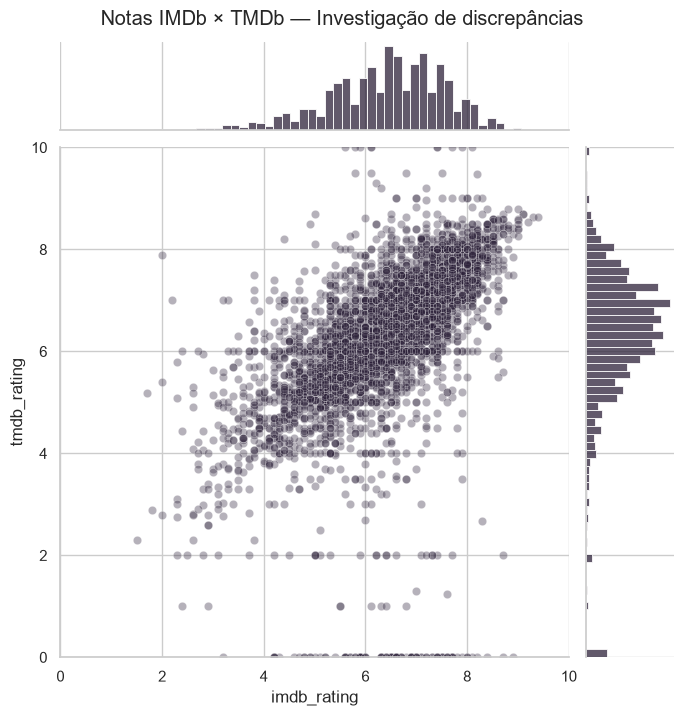

,title,tipo_conteudo,imdb_rating,tmdb_rating,diferenca_notas,match_method,match_confidence
6480,The In-Laws,Série,8.9,0.0,8.9,exact_title_year,0.90
7647,Wives on Strike,Filme,8.7,0.0,8.7,exact_title_year,0.90
3752,Love Family,Série,8.4,0.0,8.4,exact_title_year,0.90
805,Before 30,Série,8.2,0.0,8.2,exact_title_year,0.90
1524,"Crazy, Lovely, Cool",Série,8.1,0.0,8.1,exact_title_year,0.90
2306,Fukrey Boyzzz: Space Mein Fukrapanti,Filme,8.0,0.0,8.0,exact_title_year,0.90
4624,Once In A Lifetime Sessions with Nile Rodgers,Filme,8.0,0.0,8.0,fuzzy_title_year,0.89
1561,Cycle,Filme,7.9,0.0,7.9,exact_title_year,0.90
1904,Earth to Luna!,Série,7.8,0.0,7.8,exact_title_year,0.90
534,Anjaan: Special Crimes Unit,Série,7.7,0.0,7.7,exact_title_year,0.90


In [41]:

dados_discrepancias = df.dropna(
    subset=["imdb_rating", "tmdb_rating"]
).copy()


dados_discrepancias["diferenca_notas"] = (
    dados_discrepancias["imdb_rating"]
    - dados_discrepancias["tmdb_rating"]
).abs()

sns.jointplot(
    data=dados_discrepancias,
    x="imdb_rating",
    y="tmdb_rating",
    kind="scatter",
    color=COR_DESTAQUE,
    alpha=0.35,
    height=7,
    xlim=(0, 10),
    ylim=(0, 10)
)

plt.suptitle(
    "Notas IMDb × TMDb — Investigação de discrepâncias",
    y=1.02
)

plt.show()


display(
    dados_discrepancias.nlargest(10, "diferenca_notas")[[
        "title",
        "tipo_conteudo",
        "imdb_rating",
        "tmdb_rating",
        "diferenca_notas",
        "match_method",
        "match_confidence"
    ]].round(2)
)

Para discutir: existem títulos com combinações incomuns de notas IMDb e TMDb, mesmo que suas avaliações isoladas sejam plausíveis? Como devemos investigar esses casos?

Existem títulos com diferenças expressivas entre as avaliações das duas plataformas. Uma nota pode estar dentro da escala válida e, ainda assim, formar uma combinação incomum quando comparada à avaliação do mesmo título na outra fonte.

As maiores diferenças devem ser investigadas individualmente. Elas podem refletir públicos avaliadores distintos, notas TMDb iguais a zero cujo significado precisa ser verificado ou possíveis erros de correspondência entre títulos. As colunas match_method e match_confidence ajudam nessa investigação, mas não comprovam que a correspondência esteja correta.

#### Análise Multivariada

A matriz de Spearman reúne as associações entre ano de lançamento, notas IMDb e TMDb, votos e popularidade. Embora apresente várias variáveis simultaneamente, cada coeficiente corresponde à relação entre um par, sem controlar a influência das demais variáveis.

##### Matriz de Correlação

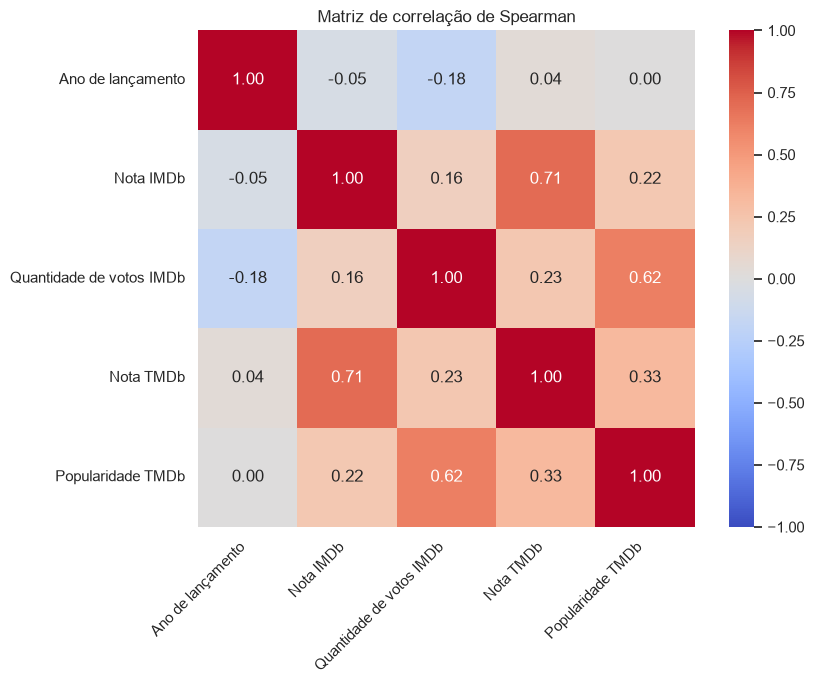

In [42]:
correlacao = df[VARS_QUANT].corr(method="spearman")

rotulos = [
    nomes_variaveis[coluna]
    for coluna in VARS_QUANT
]

plt.figure(figsize=(9, 7))

sns.heatmap(
    correlacao,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    xticklabels=rotulos,
    yticklabels=rotulos
)

plt.title("Matriz de correlação de Spearman")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

Para discutir: alguma associação sugere que duas variáveis carregam informações semelhantes? Uma correlação elevada seria suficiente para excluir uma delas?

Resposta:

As notas IMDb e TMDb apresentam associação positiva: títulos mais bem avaliados em uma plataforma tendem a receber avaliações maiores na outra. Isso indica que as duas variáveis compartilham informações sobre a avaliação dos conteúdos.

Entretanto, uma correlação elevada não significa que as notas sejam iguais ou que uma variável possa substituir completamente a outra. As plataformas podem apresentar diferenças de público, disponibilidade e valores atribuídos, como observamos na análise de discrepâncias.

Portanto, manteremos ambas nesta análise exploratória. Uma eventual exclusão dependeria do objetivo de uma análise posterior, da qualidade das informações e da contribuição de cada variável, não apenas do coeficiente de correlação.

##### Correlograma

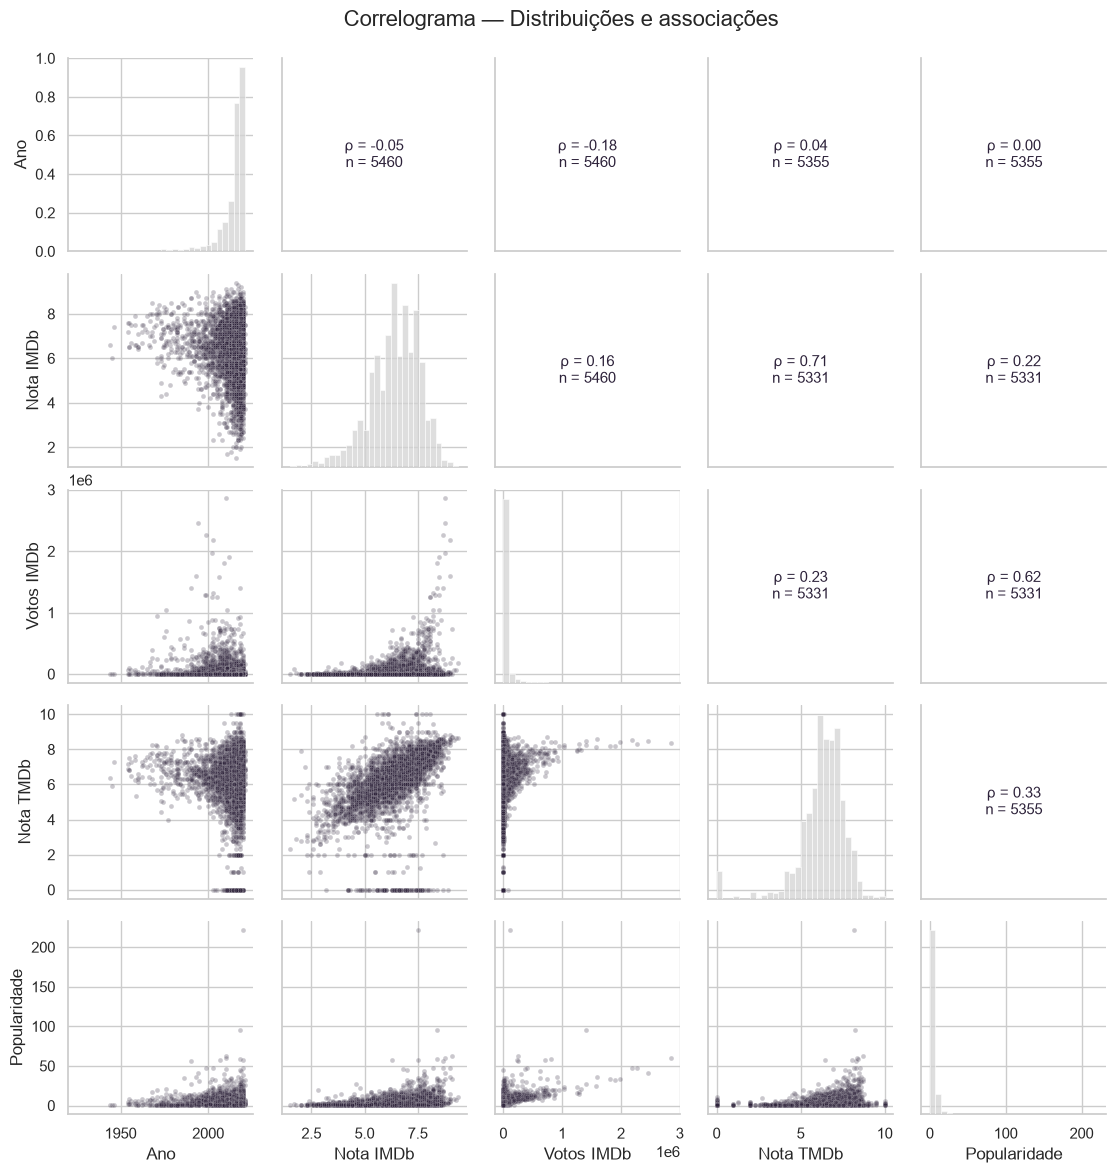

In [43]:

dados_grafico = df[VARS_QUANT].rename(columns={
    "release_year": "Ano",
    "imdb_rating": "Nota IMDb",
    "imdb_votes": "Votos IMDb",
    "tmdb_rating": "Nota TMDb",
    "tmdb_popularity": "Popularidade"
})

def mostrar_correlacao(x, y, **kwargs):

    pares = pd.DataFrame({"x": x, "y": y}).dropna()

    rho = pares["x"].corr(pares["y"], method="spearman")

    ax = plt.gca()

    ax.text(
        0.5, 0.5,
        f"ρ = {rho:.2f}\nn = {len(pares)}",
        ha="center",
        va="center",
        transform=ax.transAxes,
        fontsize=11,
        color=COR_DESTAQUE
    )

    ax.grid(False)

g = sns.PairGrid(
    dados_grafico,
    diag_sharey=False,
    height=2.3
)

g.map_diag(
    sns.histplot,
    bins=30,
    color=COR_NEUTRA
)

g.map_lower(
    sns.scatterplot,
    color=COR_DESTAQUE,
    alpha=0.25,
    s=12
)

g.map_upper(mostrar_correlacao)

g.fig.suptitle(
    "Correlograma — Distribuições e associações",
    y=1.02,
    fontsize=16
)

plt.show()

Para discutir: o que o correlograma acrescenta à análise da matriz de correlação?

O correlograma permite observar o formato das distribuições e das relações, complementando os coeficientes numéricos. Os histogramas evidenciam a assimetria de votos e popularidade, enquanto os gráficos de dispersão ajudam a identificar concentração de títulos, valores extremos e possíveis padrões não lineares.

Na comparação entre notas IMDb e TMDb, podemos avaliar visualmente a associação positiva e as discrepâncias entre avaliações. Assim, o gráfico ajuda a evitar conclusões baseadas apenas na intensidade de um coeficiente.

Os valores extremos de votos e popularidade podem comprimir grande parte dos pontos na escala original, dificultando a leitura. Além disso, cada par utiliza os registros disponíveis, de modo que as correlações não necessariamente representam exatamente o mesmo conjunto de títulos.

## Síntese e principais conclusões

A análise exploratória investigou a composição da base, a disponibilidade das informações, as distribuições e as relações entre características dos títulos.

### 1. Predominância de filmes

Dos **7.786 títulos**, **5.376 são filmes** e **2.410 são séries**, correspondendo a aproximadamente **69% e 31%**, respectivamente. Essa diferença de tamanho justifica o uso de percentuais nas comparações entre os grupos.

### 2. Disponibilidade desigual de avaliações

Aproximadamente **73,75% dos filmes** possuem nota IMDb, contra **62,03% das séries**. Além disso, **2.302 títulos** estão sem notas IMDb e TMDb simultaneamente.

A relação com o método de correspondência entre fontes sugere que parte das ausências está associada ao processo de integração dos dados, sem comprovar sua causa.

### 3. Avaliações mais altas nas séries entre os títulos avaliados

A mediana das notas IMDb é **7,1 para séries** e **6,3 para filmes**. Os testes de Welch e Mann-Whitney indicaram diferenças estatisticamente significativas entre os grupos.

Entretanto, isso não demonstra que ser uma série cause notas maiores. A cobertura desigual das avaliações também limita a generalização dos resultados.

### 4. Forte assimetria em votos e popularidade

Poucos títulos apresentam quantidades de votos e valores de popularidade muito superiores aos demais. Esses registros foram preservados, pois não houve confirmação de erro.

A transformação logarítmica dos votos foi utilizada para explorar a distribuição em outra escala, mantendo os valores originais.

### 5. Associação entre avaliações e diferenças entre categorias

Notas maiores no IMDb tendem a acompanhar notas maiores no TMDb, embora existam discrepâncias entre títulos. Portanto, as avaliações estão associadas, mas não são equivalentes.

Também foram encontradas diferenças nas avaliações entre os gêneros selecionados e associação entre tipo de conteúdo e classificação indicativa. Esses resultados representam **associações exploratórias, não relações causais**.

### Limitações da análise

- **Dados ausentes:** cada análise utilizou os registros com as informações necessárias, podendo representar subconjuntos diferentes.
- **Integração entre fontes:** possíveis inconsistências de correspondência entre títulos podem afetar os resultados.
- **Testes exploratórios:** não foi aplicado ajuste conjunto para múltiplas comparações. Os p-valores não medem a importância prática das diferenças.
- **Abrangência temporal:** os anos de lançamento vão até 2021. A base não deve ser interpretada como um retrato do catálogo atual da Netflix.
- **Preservação dos dados:** a igualdade das distribuições antes e depois confirma que os valores originais foram mantidos, mas não significa que as limitações da base tenham sido resolvidas.

## Declaração de uso de inteligência artificial

### 1. Ferramenta utilizada

**ChatGPT**

### 2. Finalidade do uso

A ferramenta foi utilizada como apoio para:

- Compreender as orientações da atividade.
- Adaptar os exemplos do dataset Heart Disease para a base Netflix.
- Elaborar e ajustar códigos em Python.
- Interpretar tabelas, gráficos e testes estatísticos.
- Investigar erros de execução.
- Organizar as discussões e conclusões do notebook.

### 3. Sugestões aceitas

Foram incorporadas sugestões de códigos e explicações para analisar dados ausentes, distribuições, outliers, correlações e diferenças entre grupos.

Também foram utilizadas sugestões para adaptar títulos, legendas e perguntas ao contexto do dataset.

## Exportação para o projeto Streamlit

Execute o notebook do início ao fim. A exportação utiliza `df`, com todos os títulos, e não o subconjunto `df_notas`.


In [44]:
# Exportação exigida na Aula 21: bruto e tratado são arquivos distintos.
# A base principal preserva ausências e extremos conforme as decisões da EDA.
assert len(df_raw) == len(df)
assert df_raw.equals(df[df_raw.columns])
assert {"tipo_conteudo", "imdb_votes_log"}.issubset(df.columns)
df_raw.to_csv(PASTA_RAW / "dataset.csv", index=False, encoding="utf-8-sig")
df.to_csv(PASTA_CLEAN / "dataset.csv", index=False, encoding="utf-8-sig")
print(f"Bruto: {df_raw.shape[0]} linhas x {df_raw.shape[1]} colunas")
print(f"Tratado: {df.shape[0]} linhas x {df.shape[1]} colunas")
print(f"Arquivo para Streamlit: {PASTA_CLEAN / 'dataset.csv'}")


Bruto: 7786 linhas x 40 colunas
Tratado: 7786 linhas x 42 colunas
Arquivo para Streamlit: C:\Users\jpedr\Documents\Codex\2026-10-25\va\outputs\netflix-streamlit\data\clean\dataset.csv


### Complemento da declaração de IA — Aula 21

Em 25/10/2026, ChatGPT/Codex adaptou o carregamento para arquivos locais e Colab, preservou uma cópia bruta, removeu referências remanescentes ao exemplo clínico e acrescentou a exportação. As decisões estatísticas da EDA foram preservadas. Não foi feita revisão humana pelo aluno nesta etapa automatizada.
